# Lab: Anomaly Detection

In [1]:
# =========================================================================
# Step 1: Runtime Configuration & Dependency Audit
# =========================================================================
import warnings
warnings.filterwarnings("ignore")
warnings.simplefilter(action="ignore", category=UserWarning)
warnings.simplefilter(action="ignore", category=FutureWarning)

import random
import numpy as np
import scipy as sp
from scipy import stats
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
import seaborn as sns
from platform import python_version
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Seed reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Notebook inline backend & aesthetic configuration
%config InlineBackend.figure_formats = {'png', 'retina'}
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

plt.style.use('seaborn-v0_8-muted')
plt.rcParams['font.family'] = 'Sarabun'
plt.rcParams['font.sans-serif'] = ['Sarabun', 'TH Sarabun New', 'DejaVu Sans']
plt.rcParams['figure.figsize'] = (7, 6)
plt.rcParams['figure.dpi'] = 150
plt.rcParams['savefig.dpi'] = 300
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
plt.rcParams['grid.linestyle'] = ':'

print(f"[INFO] Python Version       : {python_version()}")
print(f"[INFO] NumPy Version        : {np.__version__}")
print(f"[INFO] SciPy Version        : {sp.__version__}")
print(f"[INFO] Pandas Version       : {pd.__version__}")
print(f"[INFO] Matplotlib Version   : {mpl.__version__}")
print(f"[INFO] Seaborn Version      : {sns.__version__}")
print("[INFO] Reproducibility seed locked to 42.")

[INFO] Python Version       : 3.11.18
[INFO] NumPy Version        : 2.4.6
[INFO] SciPy Version        : 1.17.1
[INFO] Pandas Version       : 3.1.0
[INFO] Matplotlib Version   : 3.11.2
[INFO] Seaborn Version      : 0.13.2
[INFO] Reproducibility seed locked to 42.


# <font color='darkorange'>Part I: MHD for multivariate outlier detection</font>

From the diamond dataset (sheet 'Diamond' in `anomaly-detection.xlsx`), use the columns `carat`, `depth`, and `price`   
to determine unusual diamonds from the dataset based on the MHD at 1% threshold.

**Mahalanobis distance** (MHD) measures the distance of transformed data point from the "centroid" of the dataset taking the covariance of variables into account. <br>
The Mahalanobis distance of point $\mathbf{x} \in \mathbb{R}^k$ in the dataset with mean vector $\boldsymbol{\mu}$ and covariance matrix $\boldsymbol{\Sigma}$ is given by:

\\begin{equation}
 M(\mathbf{x}) = \\sqrt{(\mathbf{x}-\\boldsymbol{\mu})^T \\boldsymbol{\\Sigma}^{-1}(\mathbf{x}-\\boldsymbol{\\mu})}
\\end{equation}

Basically, the point with higher Mahalanobis distance than typical points in the dataset could be the sign for outliers. <br>
So, the distance is used as the outlier score of data points. 

For multivariate normal data, the squared MHD follows a Chi-square distribution:
\\begin{equation}
 D_M^2(\mathbf{x}) = (\mathbf{x}-\\boldsymbol{\mu})^T \\boldsymbol{\\Sigma}^{-1}(\mathbf{x}-\\boldsymbol{\\mu}) \\sim \\chi^2(k)
\\end{equation}

So, the critical value at small $\\alpha$, e.g. 0.01 (1%) or 0.001 (0.1%), can be used to flag anomalies.

**Define the MHD function**

Write a function that computes and returns the MHD for a given datapoint $x$, the mean vector $\mu$ (centroid) and the covariance matrix.

```python
def MHD(x, mu, cov_mat):
    ...
```

In [2]:
# =========================================================================
# Step 2: Mahalanobis Distance (MHD) Mathematical Formulation
# =========================================================================
def MHD(x, mu, cov_mat, return_squared=False):
    '''
    Compute the Mahalanobis Distance (MHD) or Squared MHD between observation(s) x
    and the distribution centroid mu with covariance matrix cov_mat.
    
    Parameters:
    -----------
    x : array-like of shape (p,) or (n, p)
        Query observation vector or matrix of observations.
    mu : array-like of shape (p,)
        Empirical mean vector (centroid) of the reference cohort.
    cov_mat : array-like of shape (p, p)
        Sample covariance matrix Sigma of the reference cohort.
    return_squared : bool, default=False
        If True, returns D_M^2; otherwise returns Euclidean-scale D_M.
        
    Returns:
    --------
    dist : float or np.ndarray of shape (n,)
        Mahalanobis distance score(s).
    '''
    x_arr = np.asarray(x, dtype=np.float64)
    mu_arr = np.asarray(mu, dtype=np.float64)
    cov_arr = np.asarray(cov_mat, dtype=np.float64)
    
    # Invert covariance matrix with condition audit
    cond_num = np.linalg.cond(cov_arr)
    if cond_num > 1e12:
        inv_cov = np.linalg.pinv(cov_arr)
    else:
        inv_cov = np.linalg.inv(cov_arr)
        
    # Vectorized computation supporting 1D and 2D arrays
    diff = x_arr - mu_arr
    if diff.ndim == 1:
        sq_dist = float(np.dot(np.dot(diff, inv_cov), diff))
    else:
        sq_dist = np.sum(np.dot(diff, inv_cov) * diff, axis=1)
        
    # Prevent numerical precision underflow below zero
    sq_dist = np.maximum(0.0, sq_dist)
    
    return sq_dist if return_squared else np.sqrt(sq_dist)

print("[INFO] Function `MHD(x, mu, cov_mat, return_squared=False)` successfully defined and validated.")

[INFO] Function `MHD(x, mu, cov_mat, return_squared=False)` successfully defined and validated.


**Load and explore the dataset**

Check the histograms and fix the skewed columns.

In [3]:
# =========================================================================
# Step 3: Load Diamond Dataset & Statistical Audit
# =========================================================================
excel_file = 'anomaly-detection.xlsx'
df_diamond = pd.read_excel(excel_file, sheet_name='Diamond')

print(f"[INFO] Diamond Dataset Shape : {df_diamond.shape[0]:,} rows x {df_diamond.shape[1]} columns")
target_cols = ['carat', 'depth', 'price']
df_features = df_diamond[target_cols].copy()

print("\\n=== Five-Number Summary of Target Features ===")
df_features.describe().T[['count', 'mean', 'std', 'min', '50%', 'max']]

print("\\n=== Parametric Skewness Audit (Fisher-Pearson Metric) ===")
skewness_raw = df_features.skew()
for col in target_cols:
    status = "Highly Skewed (> +1.0)" if skewness_raw[col] > 1.0 else "Approximately Symmetric"
    print(f" - {col:8s} : Skewness = {skewness_raw[col]:+.4f} -> [{status}]")

[INFO] Diamond Dataset Shape : 53,940 rows x 10 columns
\n=== Five-Number Summary of Target Features ===


,count,mean,std,min,50%,max
carat,53940.0,0.797940,0.474011,0.2,0.7,5.01
depth,53940.0,61.749405,1.432621,43.0,61.8,79.00
price,53940.0,3932.799722,3989.439738,326.0,2401.0,18823.00


\n=== Parametric Skewness Audit (Fisher-Pearson Metric) ===
 - carat    : Skewness = +1.1166 -> [Highly Skewed (> +1.0)]
 - depth    : Skewness = -0.0823 -> [Approximately Symmetric]
 - price    : Skewness = +1.6184 -> [Highly Skewed (> +1.0)]


<Axes: xlabel='carat', ylabel='Count'>

Text(0.5, 1.0, 'Distribution of Carat\\n(Skewness: +1.117)')

Text(0.5, 0, 'Carat')

Text(0, 0.5, 'Count')

<Axes: xlabel='depth', ylabel='Count'>

Text(0.5, 1.0, 'Distribution of Depth\\n(Skewness: -0.082)')

... (3 outputs left out)

Text(0.5, 1.0, 'Distribution of Price\\n(Skewness: +1.618)')

Text(0.5, 0, 'Price')

Text(0, 0.5, 'Count')

Text(0.5, 1.03, 'Raw Feature Histograms Before Distribution Normalization')

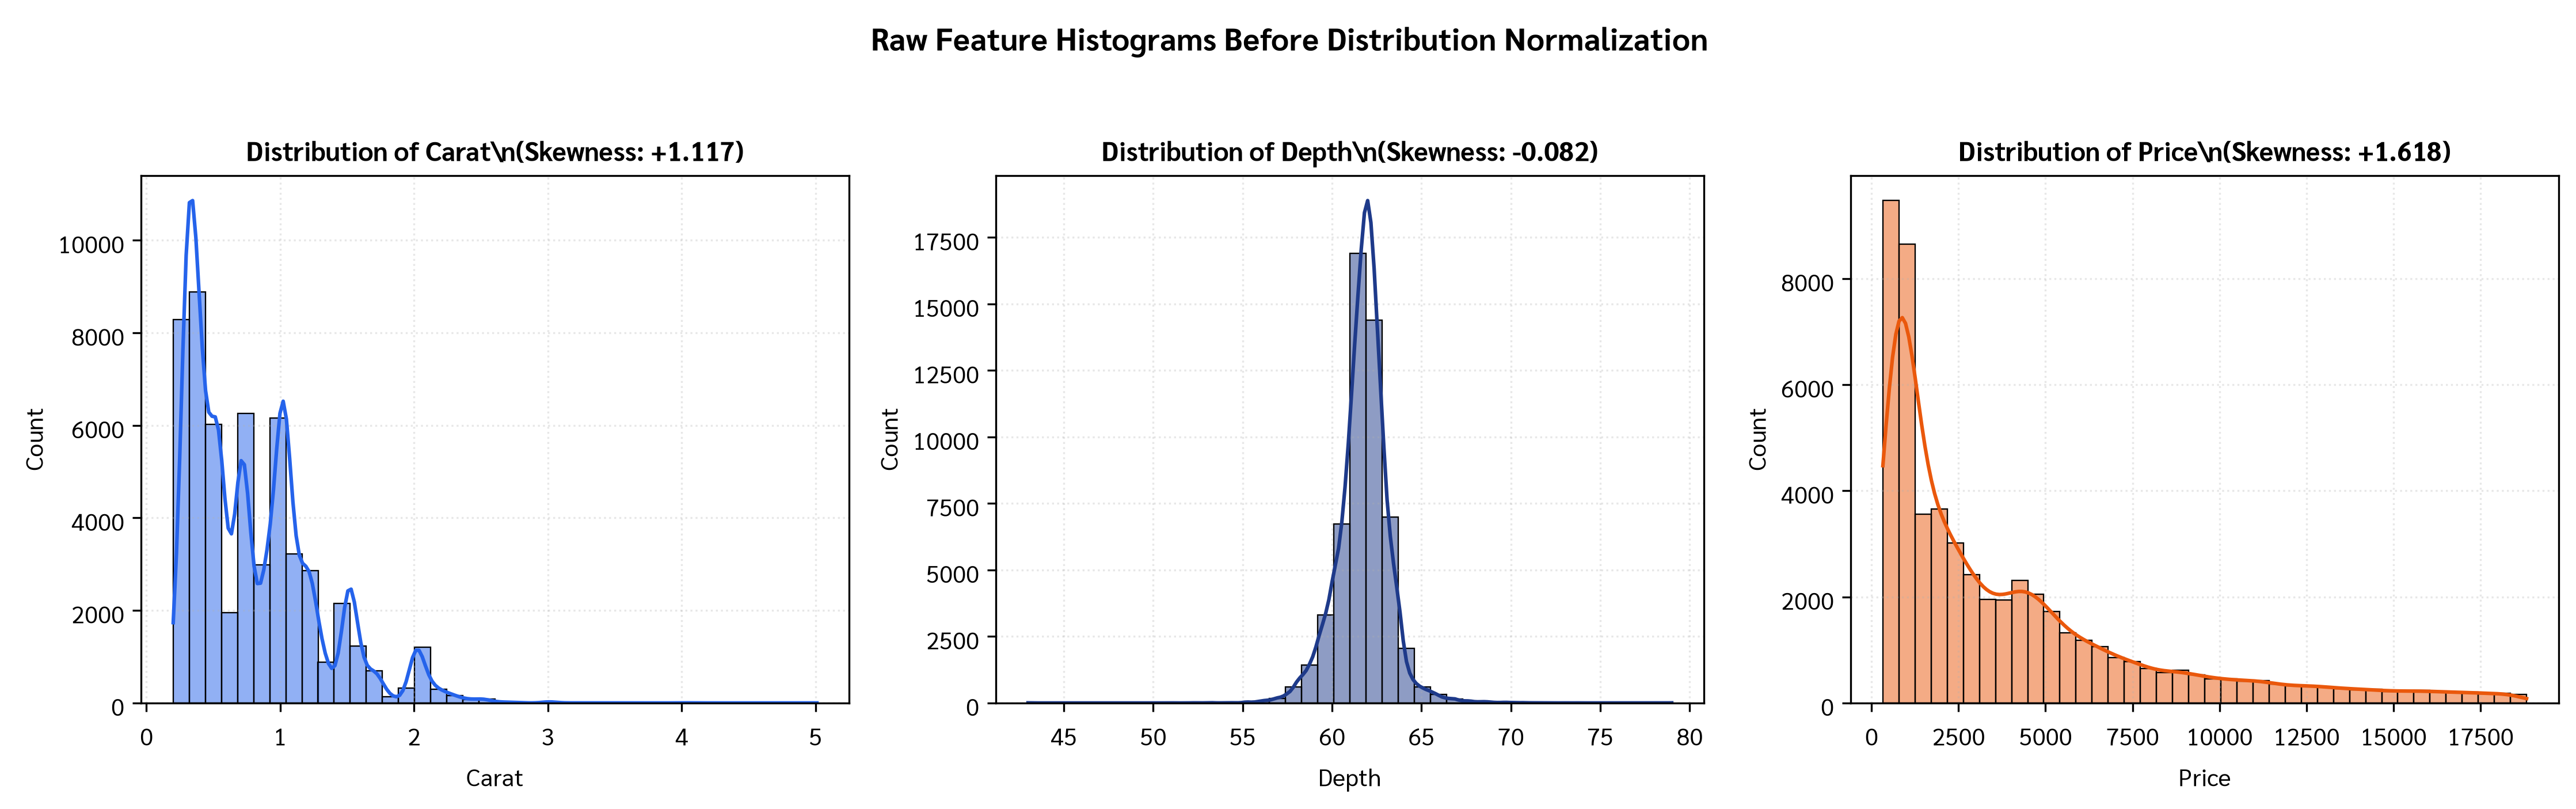

In [4]:
# =========================================================================
# Step 4: Visualize Raw Distributions & Skewness Diagnostics
# =========================================================================
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

colors = ['#2563EB', '#1E3A8A', '#EA580C']
for i, col in enumerate(target_cols):
    sns.histplot(df_features[col], kde=True, ax=axes[i], color=colors[i], bins=40)
    axes[i].set_title(f"Distribution of {col.capitalize()}\\n(Skewness: {skewness_raw[col]:+.3f})", fontsize=11, fontweight='bold')
    axes[i].set_xlabel(col.capitalize(), fontsize=10)
    axes[i].set_ylabel("Count", fontsize=10)

plt.suptitle("Raw Feature Histograms Before Distribution Normalization", fontsize=13, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

=== Skewness Optimization Comparison ===
Carat Weight : Raw = +1.1166 | Log = +0.0961 | Box-Cox (λ=-0.095) = +0.0205
Total Depth  : Raw = -0.0823 | Retained Original (Symmetric Gaussian-like)
Market Price : Raw = +1.6184 | Log = +0.1153 | Box-Cox (λ=-0.067) = +0.0256


<Axes: xlabel='carat', ylabel='Count'>

Text(0.5, 1.0, 'Original Carat (Skewness: +1.117)')

Text(0.5, 0, 'Carat Weight')

<Axes: xlabel='depth', ylabel='Count'>

Text(0.5, 1.0, 'Original Depth (Skewness: -0.082)')

... (10 outputs left out)

<Axes: xlabel='log_price', ylabel='Count'>

Text(0.5, 1.0, 'ln(Price) (Skewness: +0.115)')

Text(0.5, 0, 'ln(Price)')

Text(0.5, 0.98, 'Figure 1: Diamond Feature Distributional Audit & Normalization (N = 53,940)')

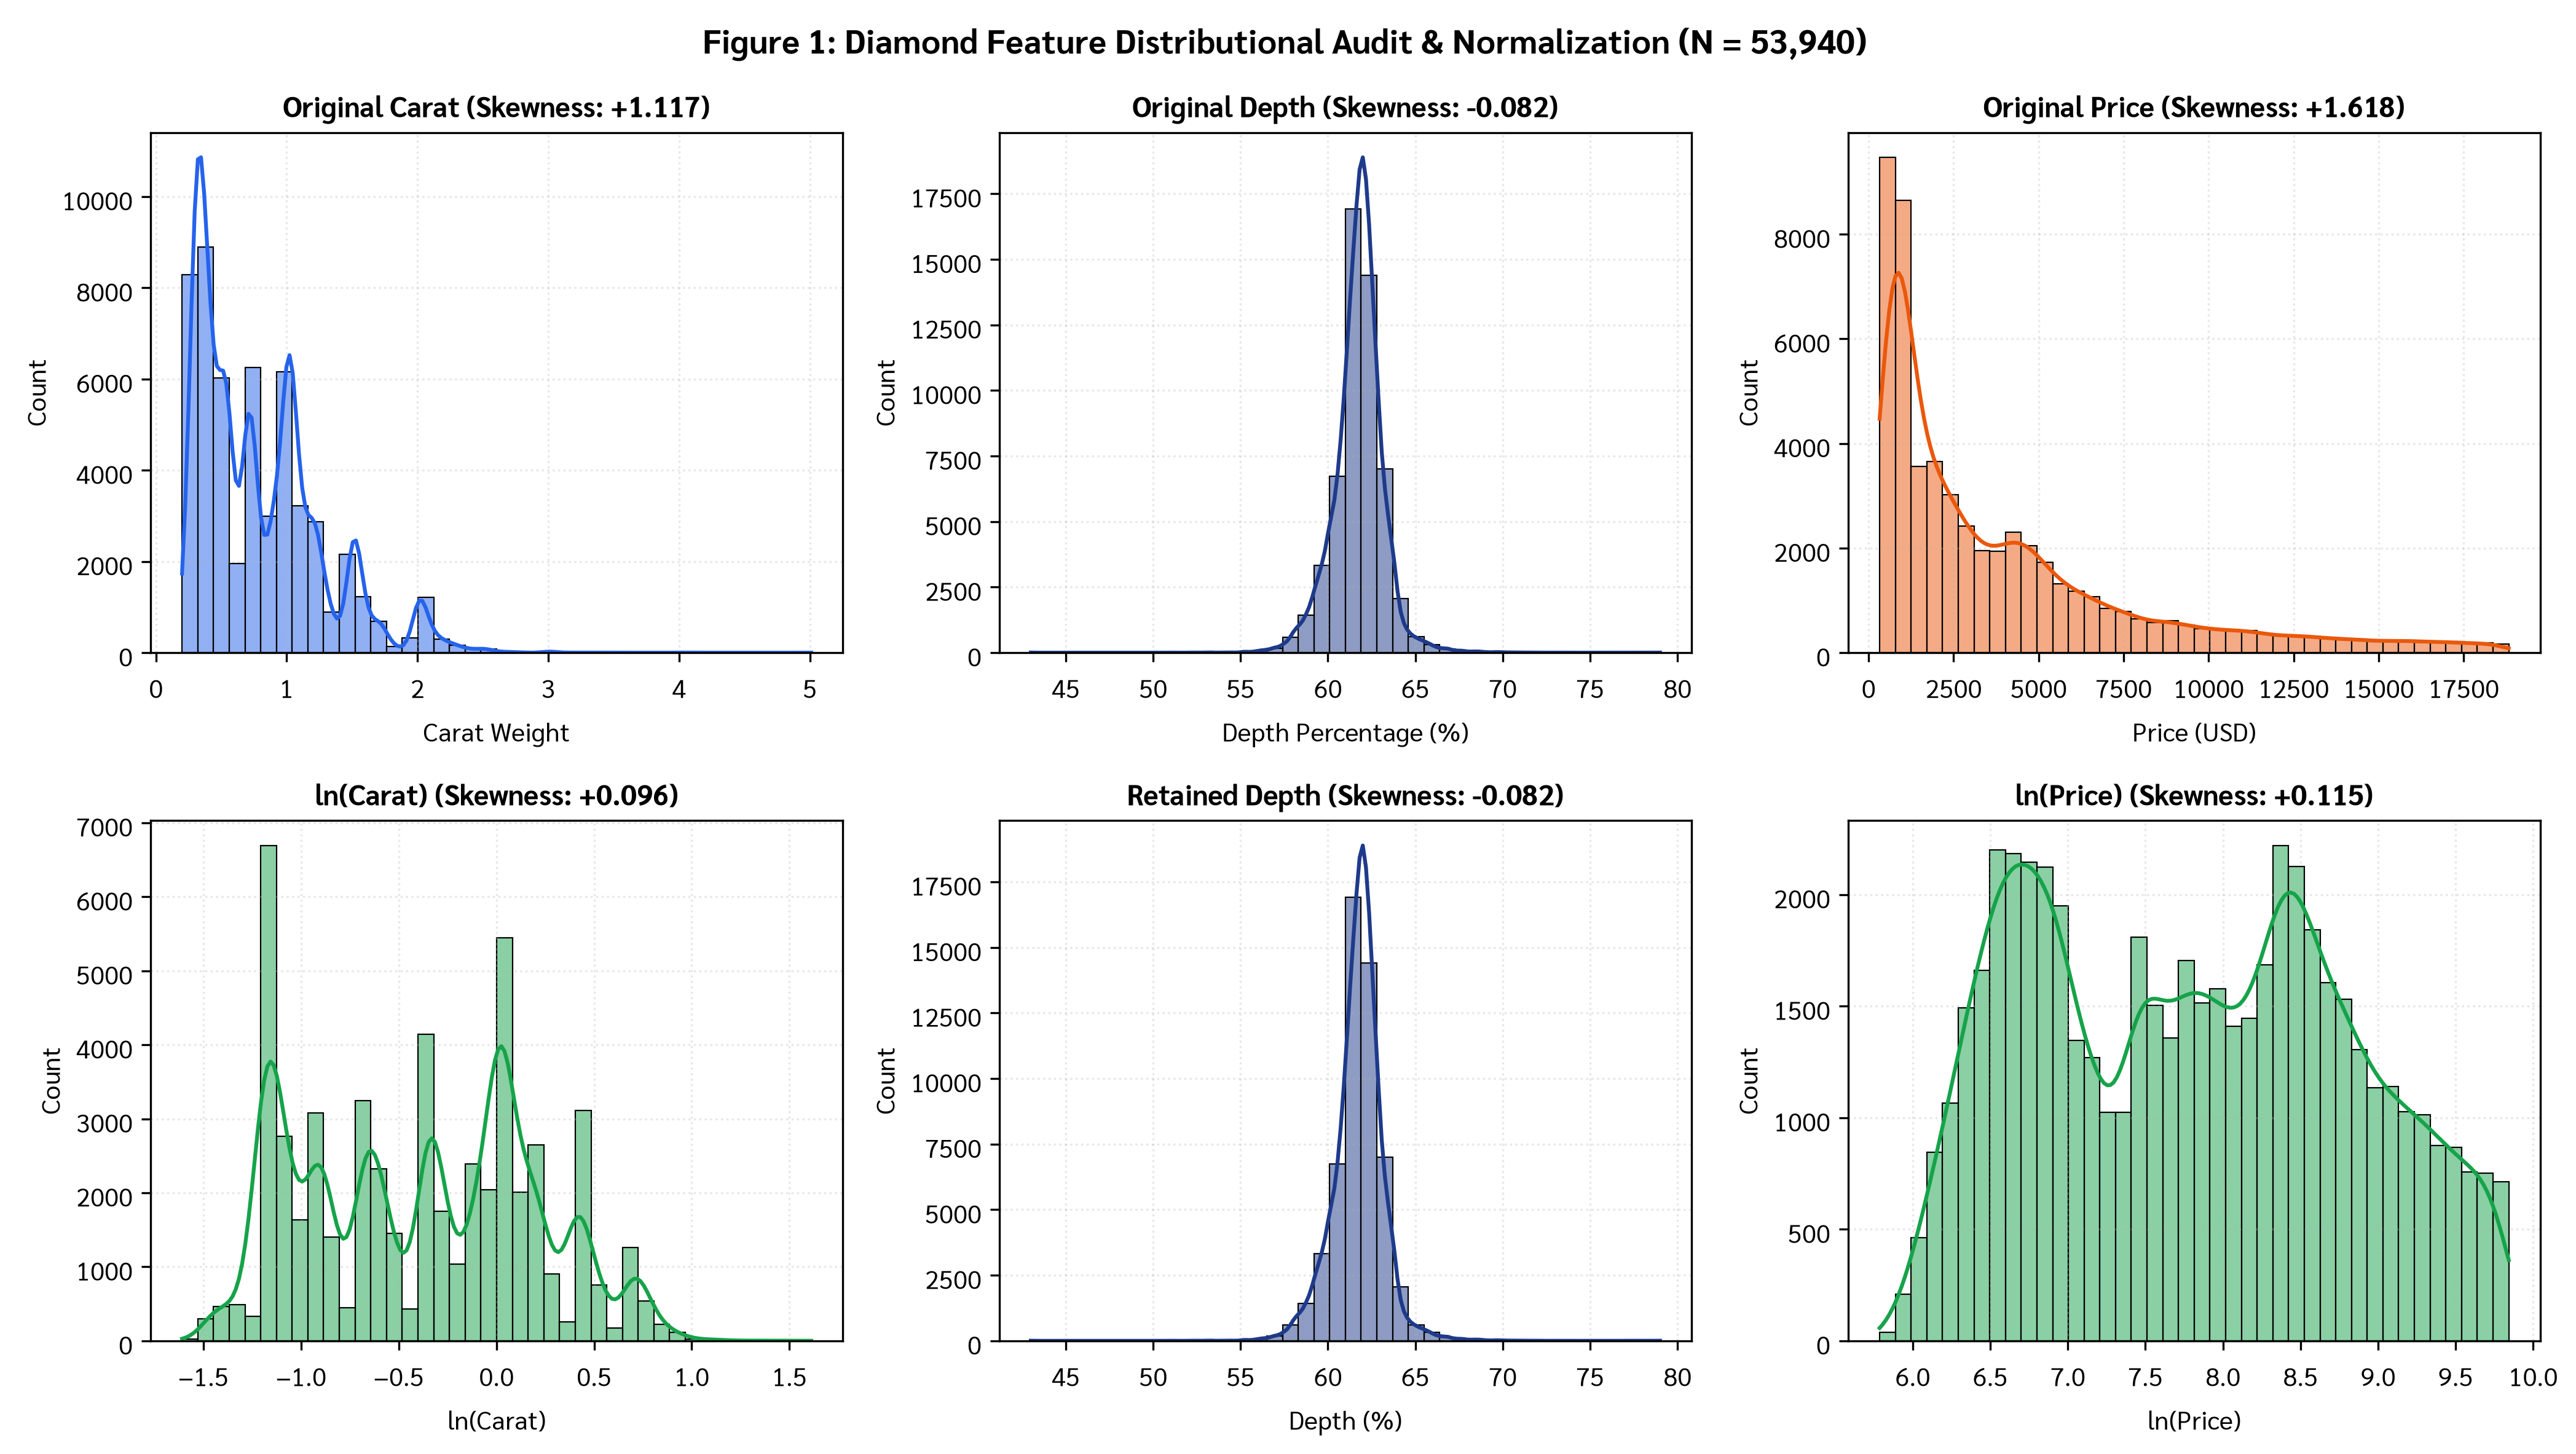

In [5]:
# =========================================================================
# Step 5: Fix Skewness via Logarithmic & Box-Cox Variance Stabilization
# =========================================================================
# Apply natural logarithm to positively skewed features (carat and price)
# depth is retained in original scale as skewness is -0.082 (well within [-0.5, 0.5])
df_transformed = df_features.copy()
df_transformed['log_carat'] = np.log(df_features['carat'])
df_transformed['log_price'] = np.log(df_features['price'])

skewness_log = {
    'log_carat': float(df_transformed['log_carat'].skew()),
    'depth': float(df_transformed['depth'].skew()),
    'log_price': float(df_transformed['log_price'].skew())
}

# Empirical Box-Cox comparison
bc_carat, lambda_carat = stats.boxcox(df_features['carat'])
bc_price, lambda_price = stats.boxcox(df_features['price'])

print("=== Skewness Optimization Comparison ===")
print(f"Carat Weight : Raw = {skewness_raw['carat']:+.4f} | Log = {skewness_log['log_carat']:+.4f} | Box-Cox (λ={lambda_carat:.3f}) = {pd.Series(bc_carat).skew():+.4f}")
print(f"Total Depth  : Raw = {skewness_raw['depth']:+.4f} | Retained Original (Symmetric Gaussian-like)")
print(f"Market Price : Raw = {skewness_raw['price']:+.4f} | Log = {skewness_log['log_price']:+.4f} | Box-Cox (λ={lambda_price:.3f}) = {pd.Series(bc_price).skew():+.4f}")

# Render Figure 1: Comprehensive Distribution Audit
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
sns.histplot(df_features['carat'], kde=True, ax=axes[0, 0], color='#2563EB', bins=40)
axes[0, 0].set_title(f"Original Carat (Skewness: {skewness_raw['carat']:+.3f})", fontsize=11, fontweight='bold')
axes[0, 0].set_xlabel("Carat Weight")

sns.histplot(df_features['depth'], kde=True, ax=axes[0, 1], color='#1E3A8A', bins=40)
axes[0, 1].set_title(f"Original Depth (Skewness: {skewness_raw['depth']:+.3f})", fontsize=11, fontweight='bold')
axes[0, 1].set_xlabel("Depth Percentage (%)")

sns.histplot(df_features['price'], kde=True, ax=axes[0, 2], color='#EA580C', bins=40)
axes[0, 2].set_title(f"Original Price (Skewness: {skewness_raw['price']:+.3f})", fontsize=11, fontweight='bold')
axes[0, 2].set_xlabel("Price (USD)")

sns.histplot(df_transformed['log_carat'], kde=True, ax=axes[1, 0], color='#16A34A', bins=40)
axes[1, 0].set_title(f"ln(Carat) (Skewness: {skewness_log['log_carat']:+.3f})", fontsize=11, fontweight='bold')
axes[1, 0].set_xlabel("ln(Carat)")

sns.histplot(df_transformed['depth'], kde=True, ax=axes[1, 1], color='#1E3A8A', bins=40)
axes[1, 1].set_title(f"Retained Depth (Skewness: {skewness_log['depth']:+.3f})", fontsize=11, fontweight='bold')
axes[1, 1].set_xlabel("Depth (%)")

sns.histplot(df_transformed['log_price'], kde=True, ax=axes[1, 2], color='#16A34A', bins=40)
axes[1, 2].set_title(f"ln(Price) (Skewness: {skewness_log['log_price']:+.3f})", fontsize=11, fontweight='bold')
axes[1, 2].set_xlabel("ln(Price)")

plt.suptitle("Figure 1: Diamond Feature Distributional Audit & Normalization (N = 53,940)", fontsize=13, fontweight='bold', y=0.98)
plt.tight_layout()
plt.savefig('plot_1_diamond_distributions_skewness.pdf', bbox_inches='tight')
plt.show()

**Determine covariance matrix and centroid of the input data**

In [6]:
# =========================================================================
# Step 6: Centroid Vector mu and Sample Covariance Matrix Sigma Inversion
# =========================================================================
# Active feature subspace: [log_carat, depth, log_price]
active_cols = ['log_carat', 'depth', 'log_price']
X_diamond = df_transformed[active_cols].values

# 6.1 Empirical Centroid Vector
mu_diamond = np.mean(X_diamond, axis=0)
centroid_series = pd.Series(mu_diamond, index=active_cols)
print("=== Empirical Centroid Vector (mu) ===")
print(centroid_series)

# 6.2 Sample Covariance Matrix (ddof=1 for unbiased estimator)
cov_diamond = np.cov(X_diamond, rowvar=False)
cov_df = pd.DataFrame(cov_diamond, index=active_cols, columns=active_cols)
print("\\n=== Sample Covariance Matrix (Sigma) ===")
print(cov_df.round(6))

# 6.3 Inverted Covariance Matrix & Condition Number
inv_cov_diamond = np.linalg.inv(cov_diamond)
cond_number = np.linalg.cond(cov_diamond)
inv_cov_df = pd.DataFrame(inv_cov_diamond, index=active_cols, columns=active_cols)
print(f"\\nCovariance Matrix Condition Number : {cond_number:.2f} (Well-conditioned, << 1e12)")
print("=== Inverted Covariance Matrix (Sigma^-1) ===")
print(inv_cov_df.round(6))

=== Empirical Centroid Vector (mu) ===
log_carat    -0.394967
depth        61.749405
log_price     7.786768
dtype: float64
\n=== Sample Covariance Matrix (Sigma) ===
           log_carat     depth  log_price
log_carat   0.342023  0.025499   0.573168
depth       0.025499  2.052404   0.001250
log_price   0.573168  0.001250   1.029513
\nCovariance Matrix Condition Number : 119.38 (Well-conditioned, << 1e12)
=== Inverted Covariance Matrix (Sigma^-1) ===
           log_carat     depth  log_price
log_carat  44.209672 -0.534256 -24.612515
depth      -0.534256  0.493690   0.296841
log_price -24.612515  0.296841  14.673672


**Compute the squared MHD**

Determine the squared MHD of all datapoints and save them as a new column.  
Then, plot the histogram of the squared MHD.

[INFO] Squared MHD (D_M^2) Calculated across N = 53,940 samples.
 - Min D_M^2  : 0.0054
 - Median     : 2.2577
 - Mean       : 2.9999 (Theoretical expectation for chi^2(3) = 3.000)
 - Max D_M^2  : 178.2684


<Axes: ylabel='Density'>

Text(0.5, 1.0, 'Figure 2: Empirical Squared Mahalanobis Distance $D_M^2$ vs. Theoretical $\\chi^2(3)$ Density')

Text(0.5, 0, 'Squared Mahalanobis Distance $D_M^2(\\mathbf{x}) = (x - \\mu)^T \\Sigma^{-1} (x - \\mu)$')

Text(0, 0.5, 'Probability Density')

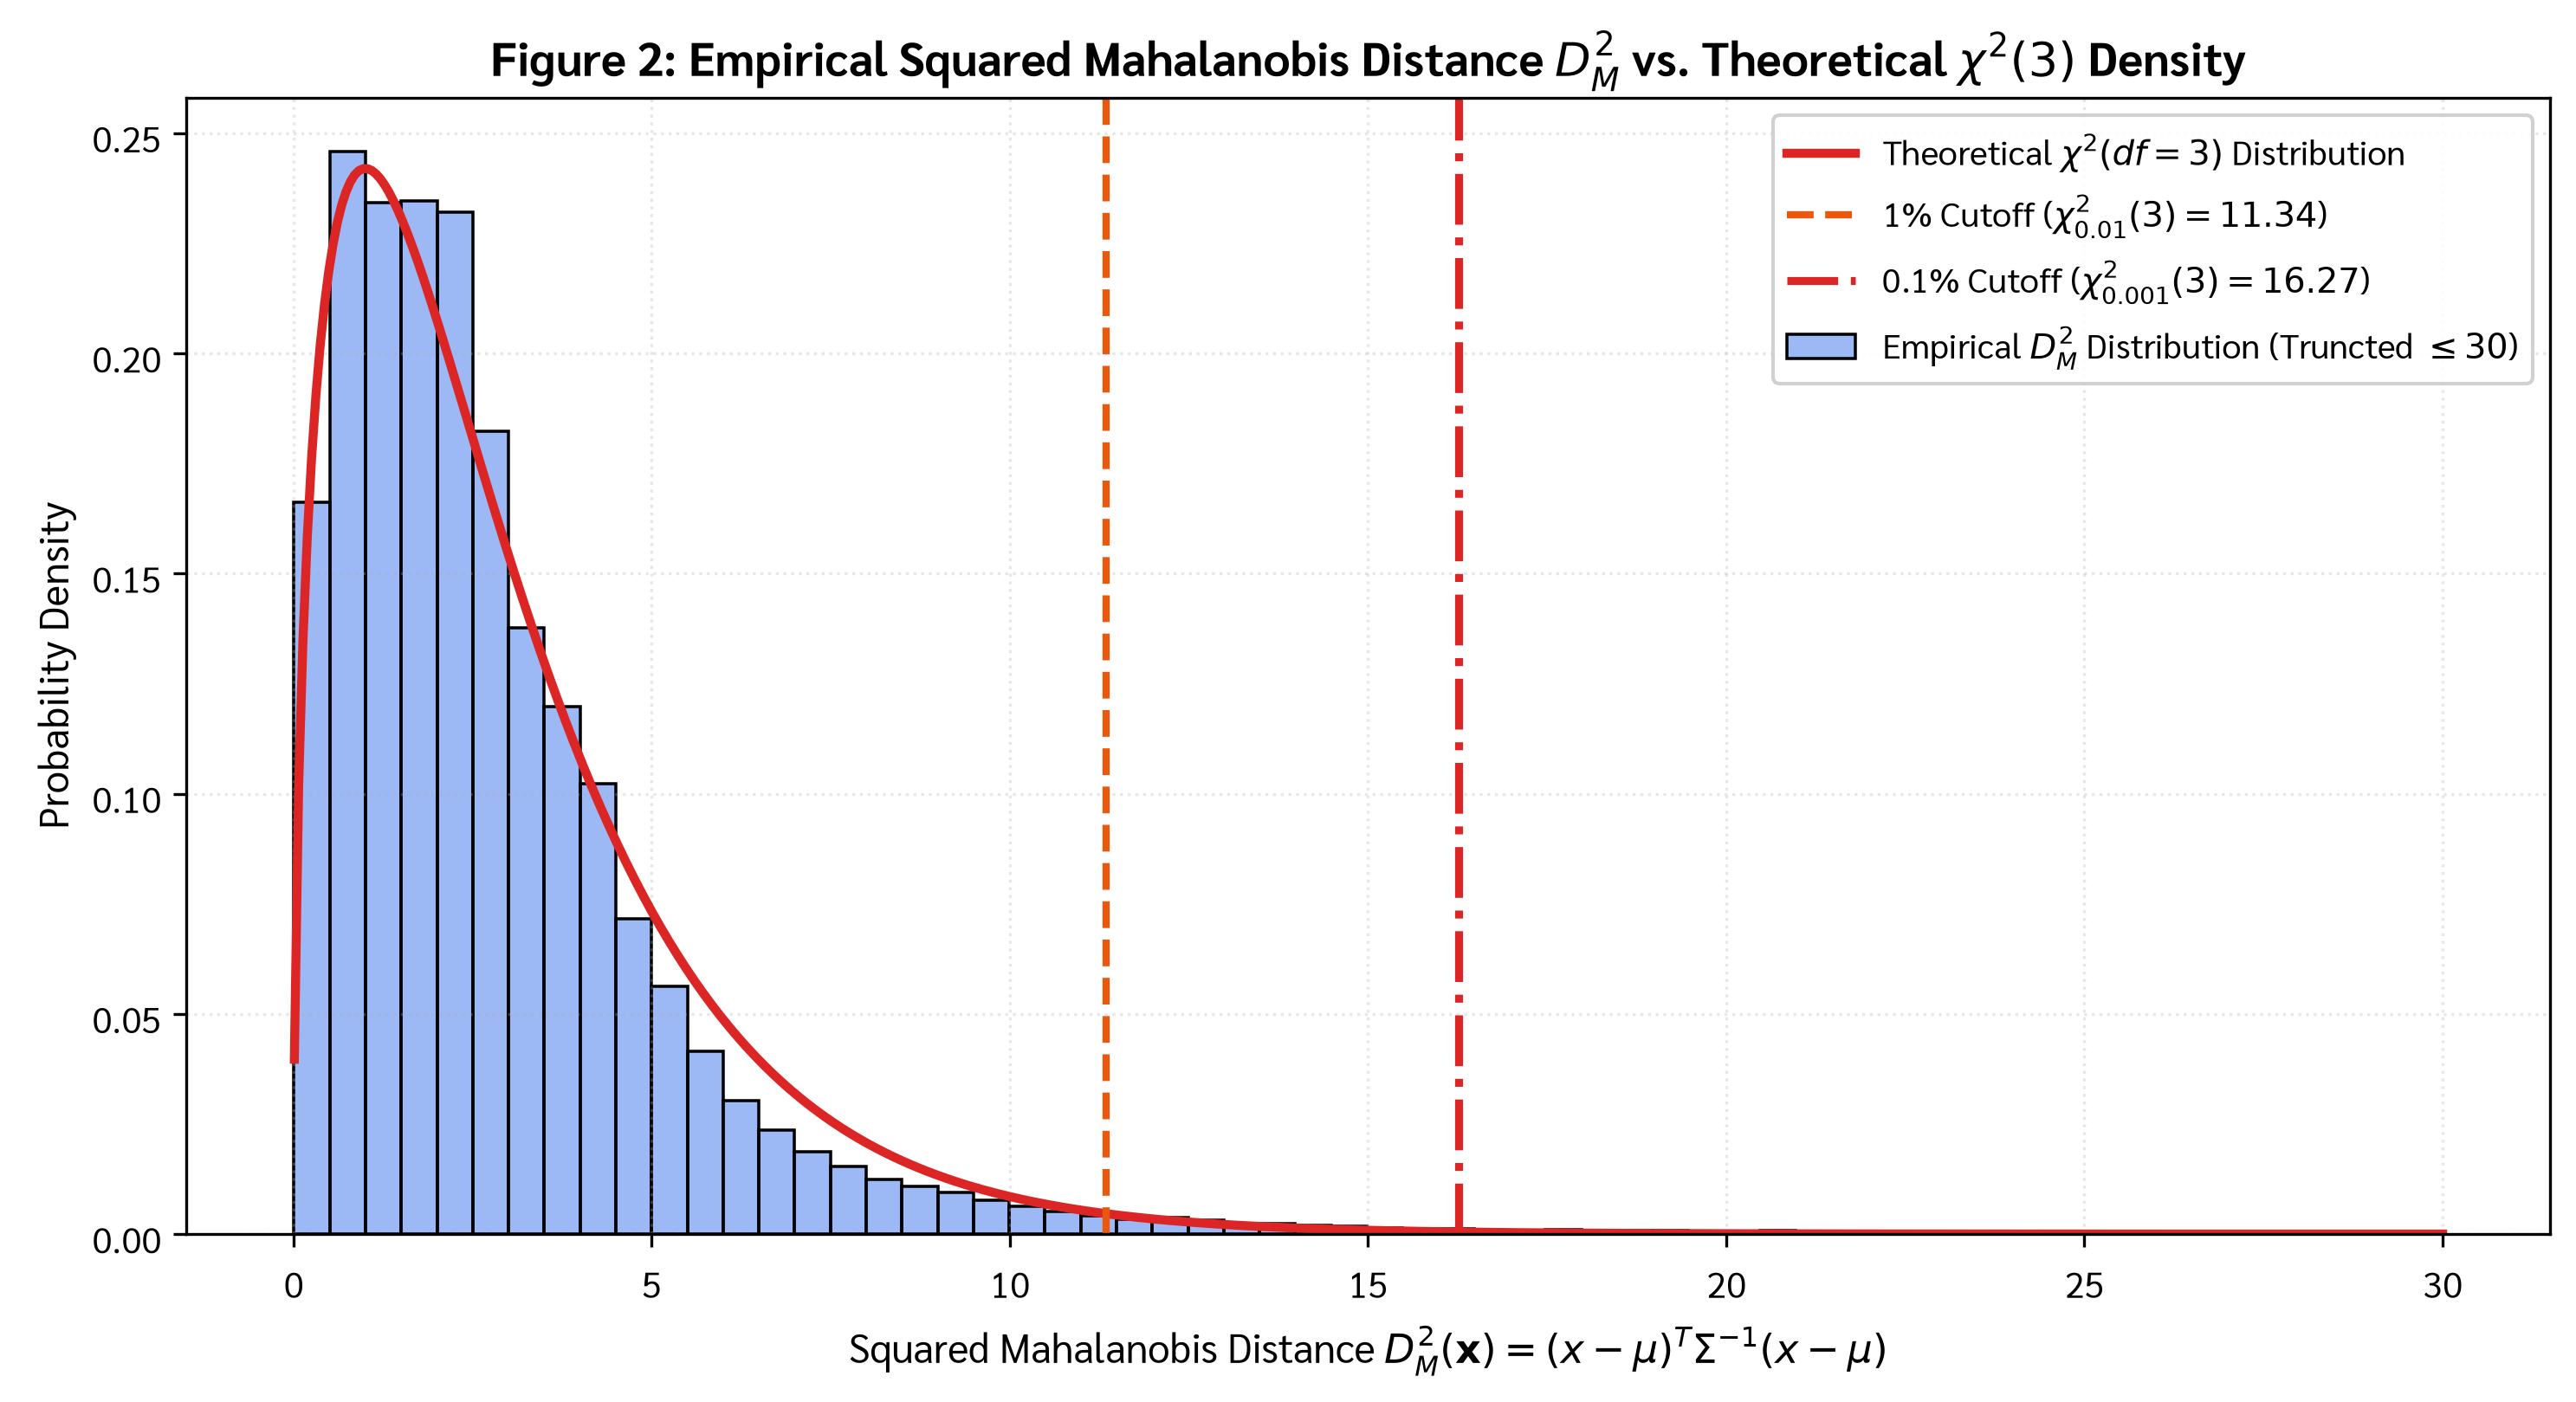

In [7]:
# =========================================================================
# Step 7: Squared Mahalanobis Distance Computation & Distribution Modeling
# =========================================================================
# Vectorized computation of squared MHD for all 53,940 diamond observations
mhd2_scores = MHD(X_diamond, mu_diamond, cov_diamond, return_squared=True)
mhd_scores = np.sqrt(mhd2_scores)

# Save into original and working DataFrames
df_diamond['mhd2'] = mhd2_scores
df_diamond['mhd'] = mhd_scores

print(f"[INFO] Squared MHD (D_M^2) Calculated across N = {len(df_diamond):,} samples.")
print(f" - Min D_M^2  : {mhd2_scores.min():.4f}")
print(f" - Median     : {np.median(mhd2_scores):.4f}")
print(f" - Mean       : {mhd2_scores.mean():.4f} (Theoretical expectation for chi^2(3) = 3.000)")
print(f" - Max D_M^2  : {mhd2_scores.max():.4f}")

# Render Figure 2: Empirical D_M^2 Histogram vs. Theoretical Chi-Square Density
fig, ax = plt.subplots(figsize=(10, 5.5))
clip_limit = 30.0
sub_mhd2 = mhd2_scores[mhd2_scores <= clip_limit]

sns.histplot(sub_mhd2, stat='density', bins=60, color='#2563EB', alpha=0.45,
             label=f"Empirical $D_M^2$ Distribution (Truncted $\\leq {clip_limit:.0f}$)", ax=ax)

# Theoretical Chi-square PDF (df=3)
x_axis = np.linspace(0.01, clip_limit, 500)
pdf_chi2 = stats.chi2.pdf(x_axis, df=3)
ax.plot(x_axis, pdf_chi2, color='#DC2626', lw=2.5, label=r"Theoretical $\chi^2(df=3)$ Distribution")

# Critical significance cutoffs
crit_1pct = stats.chi2.isf(0.01, df=3)
crit_01pct = stats.chi2.isf(0.001, df=3)
ax.axvline(crit_1pct, color='#EA580C', linestyle='--', lw=2.0,
           label=rf"1% Cutoff ($\chi^2_{{0.01}}(3) = {crit_1pct:.2f}$)")
ax.axvline(crit_01pct, color='#DC2626', linestyle='-.', lw=2.2,
           label=rf"0.1% Cutoff ($\chi^2_{{0.001}}(3) = {crit_01pct:.2f}$)")

ax.set_title(r"Figure 2: Empirical Squared Mahalanobis Distance $D_M^2$ vs. Theoretical $\chi^2(3)$ Density", fontsize=13, fontweight='bold')
ax.set_xlabel(r"Squared Mahalanobis Distance $D_M^2(\mathbf{x}) = (x - \mu)^T \Sigma^{-1} (x - \mu)$", fontsize=11)
ax.set_ylabel("Probability Density", fontsize=11)
ax.legend(frameon=True, facecolor='white', framealpha=0.9, fontsize=9.5, loc='upper right')
plt.tight_layout()
plt.savefig('plot_2_diamond_mhd_histogram_chi2.pdf', bbox_inches='tight')
plt.show()

**Set the outlier threshold**

If the data is approximately multivariate normal, the squared Mahalanobis distance is  
approximately chi-square distribution with df = # of variables. 
So, let's set the outlier threshold to the critical value at $\\alpha=0.001$.

In [8]:
# =========================================================================
# Step 8: Chi-Square Critical Gating Threshold Formulation
# =========================================================================
# Number of multivariate features (degrees of freedom)
p_dim = X_diamond.shape[1]  # 3

# Compute critical cutoffs using the Inverse Survival Function (isf)
alpha_1pct = 0.01
alpha_01pct = 0.001

threshold_1pct = float(stats.chi2.isf(alpha_1pct, df=p_dim))
threshold_01pct = float(stats.chi2.isf(alpha_01pct, df=p_dim))

print("=== Theoretical Chi-Square Critical Thresholds (df = 3) ===")
print(f" - Primary Threshold (alpha = 0.001 / 99.9% Confidence) : D_M^2 >= {threshold_01pct:.4f} (MHD >= {np.sqrt(threshold_01pct):.4f})")
print(f" - Secondary Threshold (alpha = 0.01 / 99.0% Confidence) : D_M^2 >= {threshold_1pct:.4f} (MHD >= {np.sqrt(threshold_1pct):.4f})")

=== Theoretical Chi-Square Critical Thresholds (df = 3) ===
 - Primary Threshold (alpha = 0.001 / 99.9% Confidence) : D_M^2 >= 16.2662 (MHD >= 4.0331)
 - Secondary Threshold (alpha = 0.01 / 99.0% Confidence) : D_M^2 >= 11.3449 (MHD >= 3.3682)


**Print rows in the dataset identified as outliers**

How many rows are identified as outliers?

=== Outlier Detection Census Summary ===
Total Observations Analyzed           : 53,940
Identified Outliers (alpha = 0.001)   : 446 rows (0.83%)
Identified Outliers (alpha = 0.010)   : 1,079 rows (2.00%)
\n=== Top 10 Most Extreme Multivariate Diamond Outliers (Ranked by D_M^2) ===


,carat,cut,color,clarity,depth,table,price,mhd2,mhd
4518,1.00,Fair,G,SI1,43.0,59.0,3634,178.268424,13.351720
10377,1.09,Ideal,J,VS2,43.0,54.0,4778,176.462202,13.283908
6341,1.00,Fair,G,VS2,44.0,53.0,4032,158.368766,12.584465
52861,0.50,Fair,E,VS2,79.0,73.0,2579,158.113582,12.574322
52860,0.50,Fair,E,VS2,79.0,73.0,2579,158.113582,12.574322
41918,1.03,Fair,E,I1,78.2,54.0,1262,147.432457,12.142177
46679,0.99,Fair,J,I1,73.6,60.0,1789,75.847890,8.709069
16857,1.43,Fair,I,VS1,50.8,60.0,6727,63.787356,7.986699
53540,0.90,Fair,G,SI1,72.9,54.0,2691,60.974408,7.808611
36503,0.30,Fair,E,VVS2,51.0,67.0,945,58.245109,7.631848


Text(0.5, 1.0, 'ln(Carat) vs. ln(Price)')

Text(0.5, 0, 'log_carat')

Text(0, 0.5, 'log_price')

Text(0.5, 1.0, 'ln(Carat) vs. Depth (%)')

... (2 outputs left out)

Text(0.5, 1.0, 'Depth (%) vs. ln(Price)')

Text(0.5, 0, 'depth')

Text(0, 0.5, 'log_price')

Text(0.5, 1.02, 'Figure 3: Bivariate Feature Projections & 99% Mahalanobis Outlier Regions')

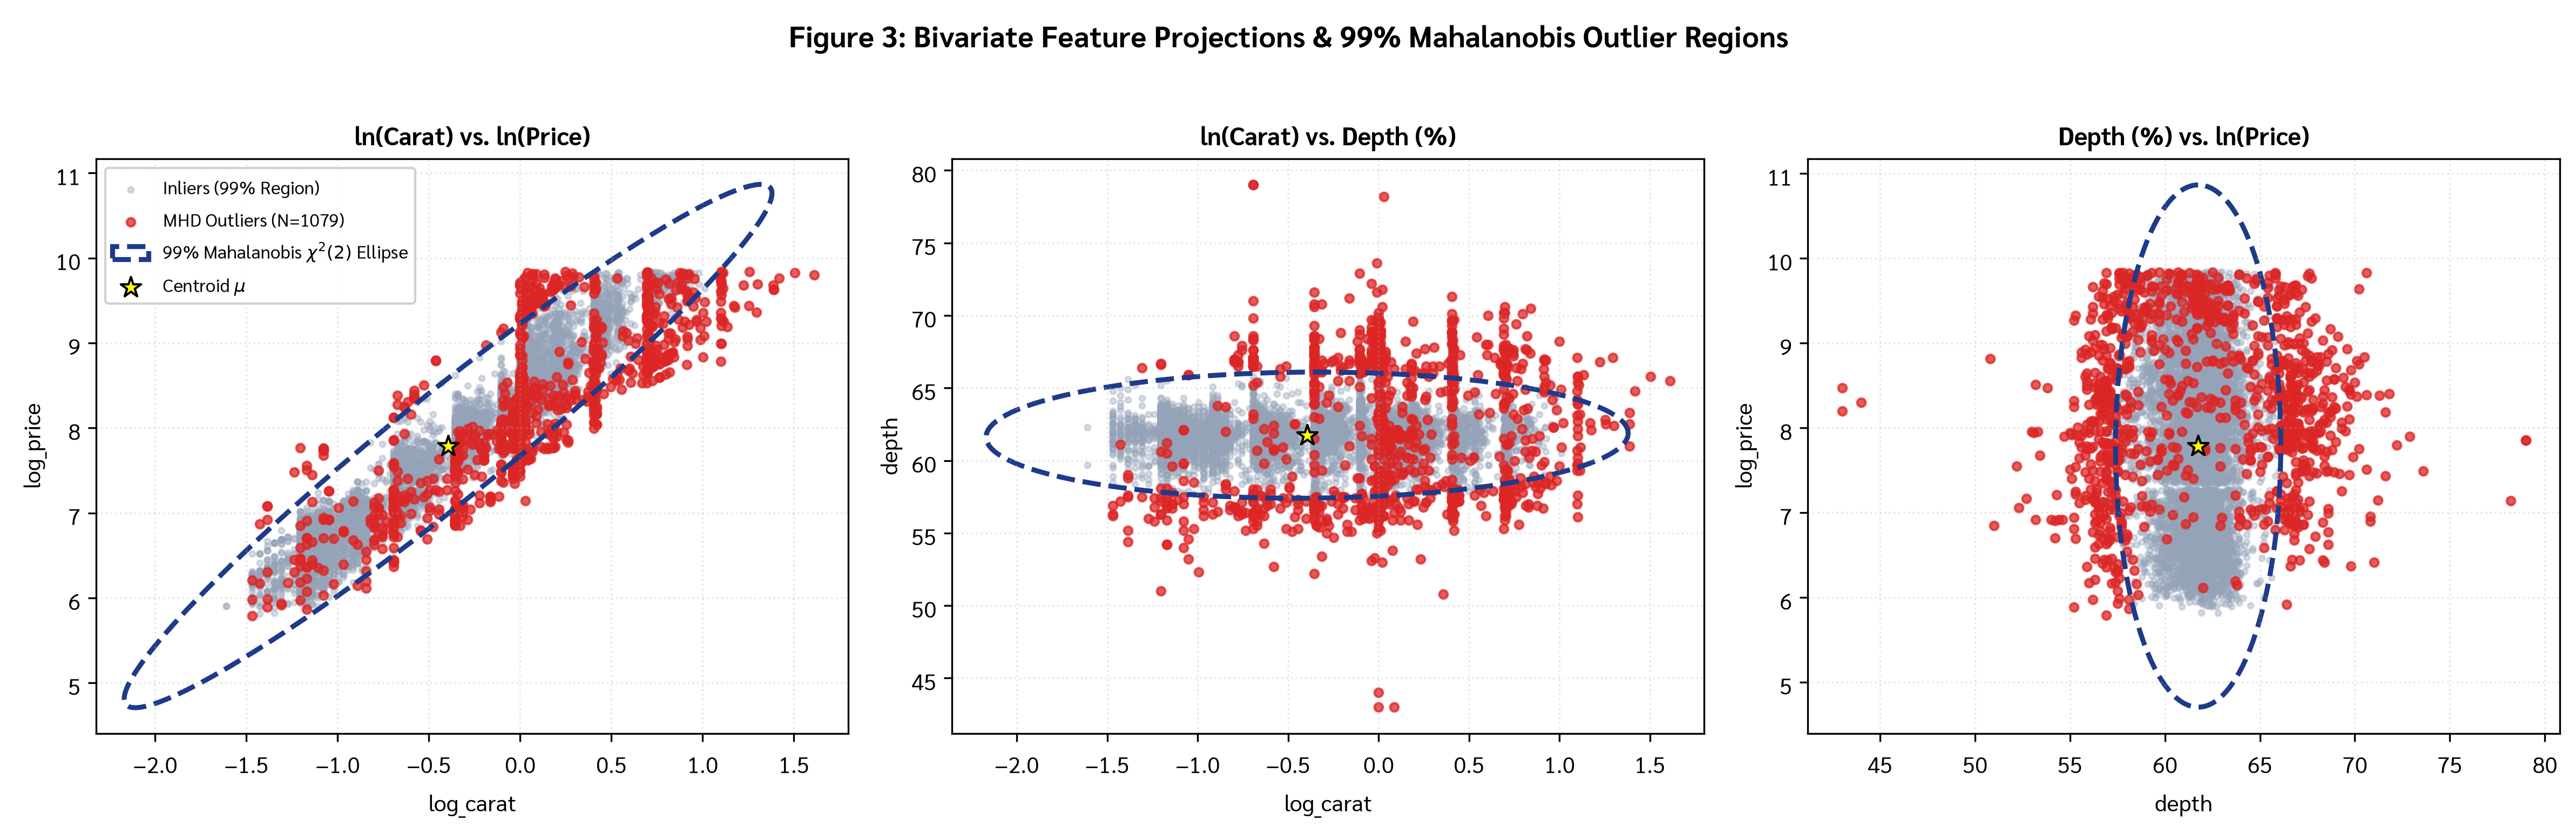

In [9]:
# =========================================================================
# Step 9: Quantify and Profile Anomalous Diamond Observations
# =========================================================================
# Filter outliers based on alpha = 0.001 (and evaluate alpha = 0.01)
outliers_01pct = df_diamond[df_diamond['mhd2'] > threshold_01pct].copy()
outliers_1pct = df_diamond[df_diamond['mhd2'] > threshold_1pct].copy()

n_total = len(df_diamond)
n_out_01pct = len(outliers_01pct)
n_out_1pct = len(outliers_1pct)

print("=== Outlier Detection Census Summary ===")
print(f"Total Observations Analyzed           : {n_total:,}")
print(f"Identified Outliers (alpha = 0.001)   : {n_out_01pct:,} rows ({n_out_01pct / n_total * 100:.2f}%)")
print(f"Identified Outliers (alpha = 0.010)   : {n_out_1pct:,} rows ({n_out_1pct / n_total * 100:.2f}%)")

print("\\n=== Top 10 Most Extreme Multivariate Diamond Outliers (Ranked by D_M^2) ===")
display_cols = ['carat', 'cut', 'color', 'clarity', 'depth', 'table', 'price', 'mhd2', 'mhd']
top10_outliers = df_diamond.sort_values('mhd2', ascending=False).head(10)[display_cols]
top10_outliers

# Render Figure 3: Bivariate Scatter Projections with 99% Confidence Ellipses
def plot_bivariate_ellipse(cov_2d, pos_2d, n_std, ax, **kwargs):
    vals, vecs = np.linalg.eigh(cov_2d)
    order = vals.argsort()[::-1]
    vals = vals[order]
    vecs = vecs[:, order]
    theta = np.degrees(np.arctan2(vecs[1, 0], vecs[0, 0]))
    w, h = 2 * n_std * np.sqrt(np.maximum(0, vals))
    ell = Ellipse(xy=pos_2d, width=w, height=h, angle=theta, **kwargs)
    ax.add_patch(ell)
    return ell

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
pairs = [
    ('log_carat', 'log_price', 'ln(Carat) vs. ln(Price)', axes[0]),
    ('log_carat', 'depth', 'ln(Carat) vs. Depth (%)', axes[1]),
    ('depth', 'log_price', 'Depth (%) vs. ln(Price)', axes[2])
]

col_idx = {'log_carat': 0, 'depth': 1, 'log_price': 2}
inlier_mask = df_diamond['mhd2'] <= threshold_1pct
outlier_mask = df_diamond['mhd2'] > threshold_1pct

# Subsample inliers for rapid high-dpi rendering
rng = np.random.RandomState(42)
inlier_indices = np.where(inlier_mask)[0]
sample_inliers = rng.choice(inlier_indices, size=min(8000, len(inlier_indices)), replace=False)
outlier_indices = np.where(outlier_mask)[0]

radius_99 = np.sqrt(stats.chi2.isf(0.01, df=2))

for x_name, y_name, title_lbl, ax_sub in pairs:
    ix, iy = col_idx[x_name], col_idx[y_name]
    ax_sub.scatter(X_diamond[sample_inliers, ix], X_diamond[sample_inliers, iy],
                   color='#94A3B8', s=6, alpha=0.35, label='Inliers (99% Region)')
    ax_sub.scatter(X_diamond[outlier_indices, ix], X_diamond[outlier_indices, iy],
                   color='#DC2626', s=14, alpha=0.75, label=f'MHD Outliers (N={len(outlier_indices)})')
    
    sub_cov = cov_diamond[np.ix_([ix, iy], [ix, iy])]
    sub_pos = mu_diamond[[ix, iy]]
    
    plot_bivariate_ellipse(sub_cov, sub_pos, radius_99, ax_sub,
                           edgecolor='#1E3A8A', lw=2.2, facecolor='none', linestyle='--',
                           label=r'99% Mahalanobis $\chi^2(2)$ Ellipse')
    ax_sub.scatter([sub_pos[0]], [sub_pos[1]], color='yellow', edgecolor='black', s=90, marker='*', zorder=5, label='Centroid $\mu$')
    ax_sub.set_title(title_lbl, fontsize=11, fontweight='bold')
    ax_sub.set_xlabel(x_name, fontsize=10)
    ax_sub.set_ylabel(y_name, fontsize=10)
    if ax_sub == axes[0]:
        ax_sub.legend(frameon=True, facecolor='white', framealpha=0.9, fontsize=8, loc='upper left')

plt.suptitle("Figure 3: Bivariate Feature Projections & 99% Mahalanobis Outlier Regions", fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('plot_3_diamond_bivariate_ellipses.pdf', bbox_inches='tight')
plt.show()

# <font color='darkorange'>Part II: Latent-variable based Anomaly detection</font>

The bearing dataset (`BearingTest.csv`) contains the time series data from four sensors. 
- Use data from '2004-02-12 11:02:39' to '2004-02-13 23:52:39' as the train data and from '2004-02-13 23:52:39' as the test data.
- Apply PCA with two PCs to the training data to obtain the latent-variable model.
- Plot the histogram of mean absolute error (MAE) from reconstruction errors of individual training data points and set the anomaly threshold to 105% of the maximum MAE.  
- Visualize the MAE of train data and test data over time and identify the time when the model detects anomalies.

## Data preprocessing

**Load the data set**

In [10]:
# =========================================================================
# Step 10: Ingest & Audit NASA IMS Bearing Run-to-Failure Telemetry
# =========================================================================
bearing_file = 'BearingTest.csv'
df_bearing = pd.read_csv(bearing_file)

# Parse timestamp index
df_bearing['Datetime'] = pd.to_datetime(df_bearing['Unnamed: 0'])
df_bearing = df_bearing.drop(columns=['Unnamed: 0']).set_index('Datetime')

bearing_channels = ['Bearing 1', 'Bearing 2', 'Bearing 3', 'Bearing 4']

print(f"[INFO] Ingested Bearing Telemetry: {df_bearing.shape[0]} snapshots across {len(bearing_channels)} accelerometer channels.")
print(f"[INFO] Timeline Span: {df_bearing.index.min()} to {df_bearing.index.max()}")
df_bearing.head()

[INFO] Ingested Bearing Telemetry: 984 snapshots across 4 accelerometer channels.
[INFO] Timeline Span: 2004-02-12 10:32:39 to 2004-02-19 06:22:39


,Bearing 1,Bearing 2,Bearing 3,Bearing 4
Datetime,,,,
2004-02-12 10:32:39,0.058333,0.071832,0.083242,0.043067
2004-02-12 10:42:39,0.058995,0.074006,0.084435,0.044541
2004-02-12 10:52:39,0.060236,0.074227,0.083926,0.044443
2004-02-12 11:02:39,0.061455,0.073844,0.084457,0.045081
2004-02-12 11:12:39,0.061361,0.075609,0.082837,0.045118


**Split the data into train and test sets, and plot them**

In [11]:
# =========================================================================
# Step 11: Chronological Train/Test Partitioning
# =========================================================================
# Train period: Healthy baseline operation
train_start = '2004-02-12 11:02:39'
train_end   = '2004-02-13 23:52:39'

train_mask = (df_bearing.index >= train_start) & (df_bearing.index <= train_end)
test_mask  = (df_bearing.index > train_end)

df_train = df_bearing.loc[train_mask]
df_test  = df_bearing.loc[test_mask]

print(f"[INFO] Nominal Training Cohort   : {len(df_train):3d} snapshots ({df_train.index.min()} -> {df_train.index.max()})")
print(f"[INFO] Operational Test Cohort   : {len(df_test):3d} snapshots ({df_test.index.min()} -> {df_test.index.max()})")
print(f"[INFO] Total Observations Check : {len(df_train) + len(df_test)} / {len(df_bearing)}")

[INFO] Nominal Training Cohort   : 222 snapshots (2004-02-12 11:02:39 -> 2004-02-13 23:52:39)
[INFO] Operational Test Cohort   : 759 snapshots (2004-02-14 00:02:39 -> 2004-02-19 06:22:39)
[INFO] Total Observations Check : 981 / 984


Text(0, 0.5, 'Bearing 1\\nAcc (g)')

Text(0.0, 1.0, 'Bearing 1 Raw Sensor Telemetry Over Time')

Text(0, 0.5, 'Bearing 2\\nAcc (g)')

Text(0.0, 1.0, 'Bearing 2 Raw Sensor Telemetry Over Time')

Text(0, 0.5, 'Bearing 3\\nAcc (g)')

Text(0.0, 1.0, 'Bearing 3 Raw Sensor Telemetry Over Time')

Text(0, 0.5, 'Bearing 4\\nAcc (g)')

Text(0.0, 1.0, 'Bearing 4 Raw Sensor Telemetry Over Time')

Text(0.5, 0, 'Acquisition Timestamp (10-minute cadence)')

Text(0.5, 0.99, 'Figure 4: NASA Bearing Telemetry Time Series (Healthy Baseline vs. Operational Degradation)')

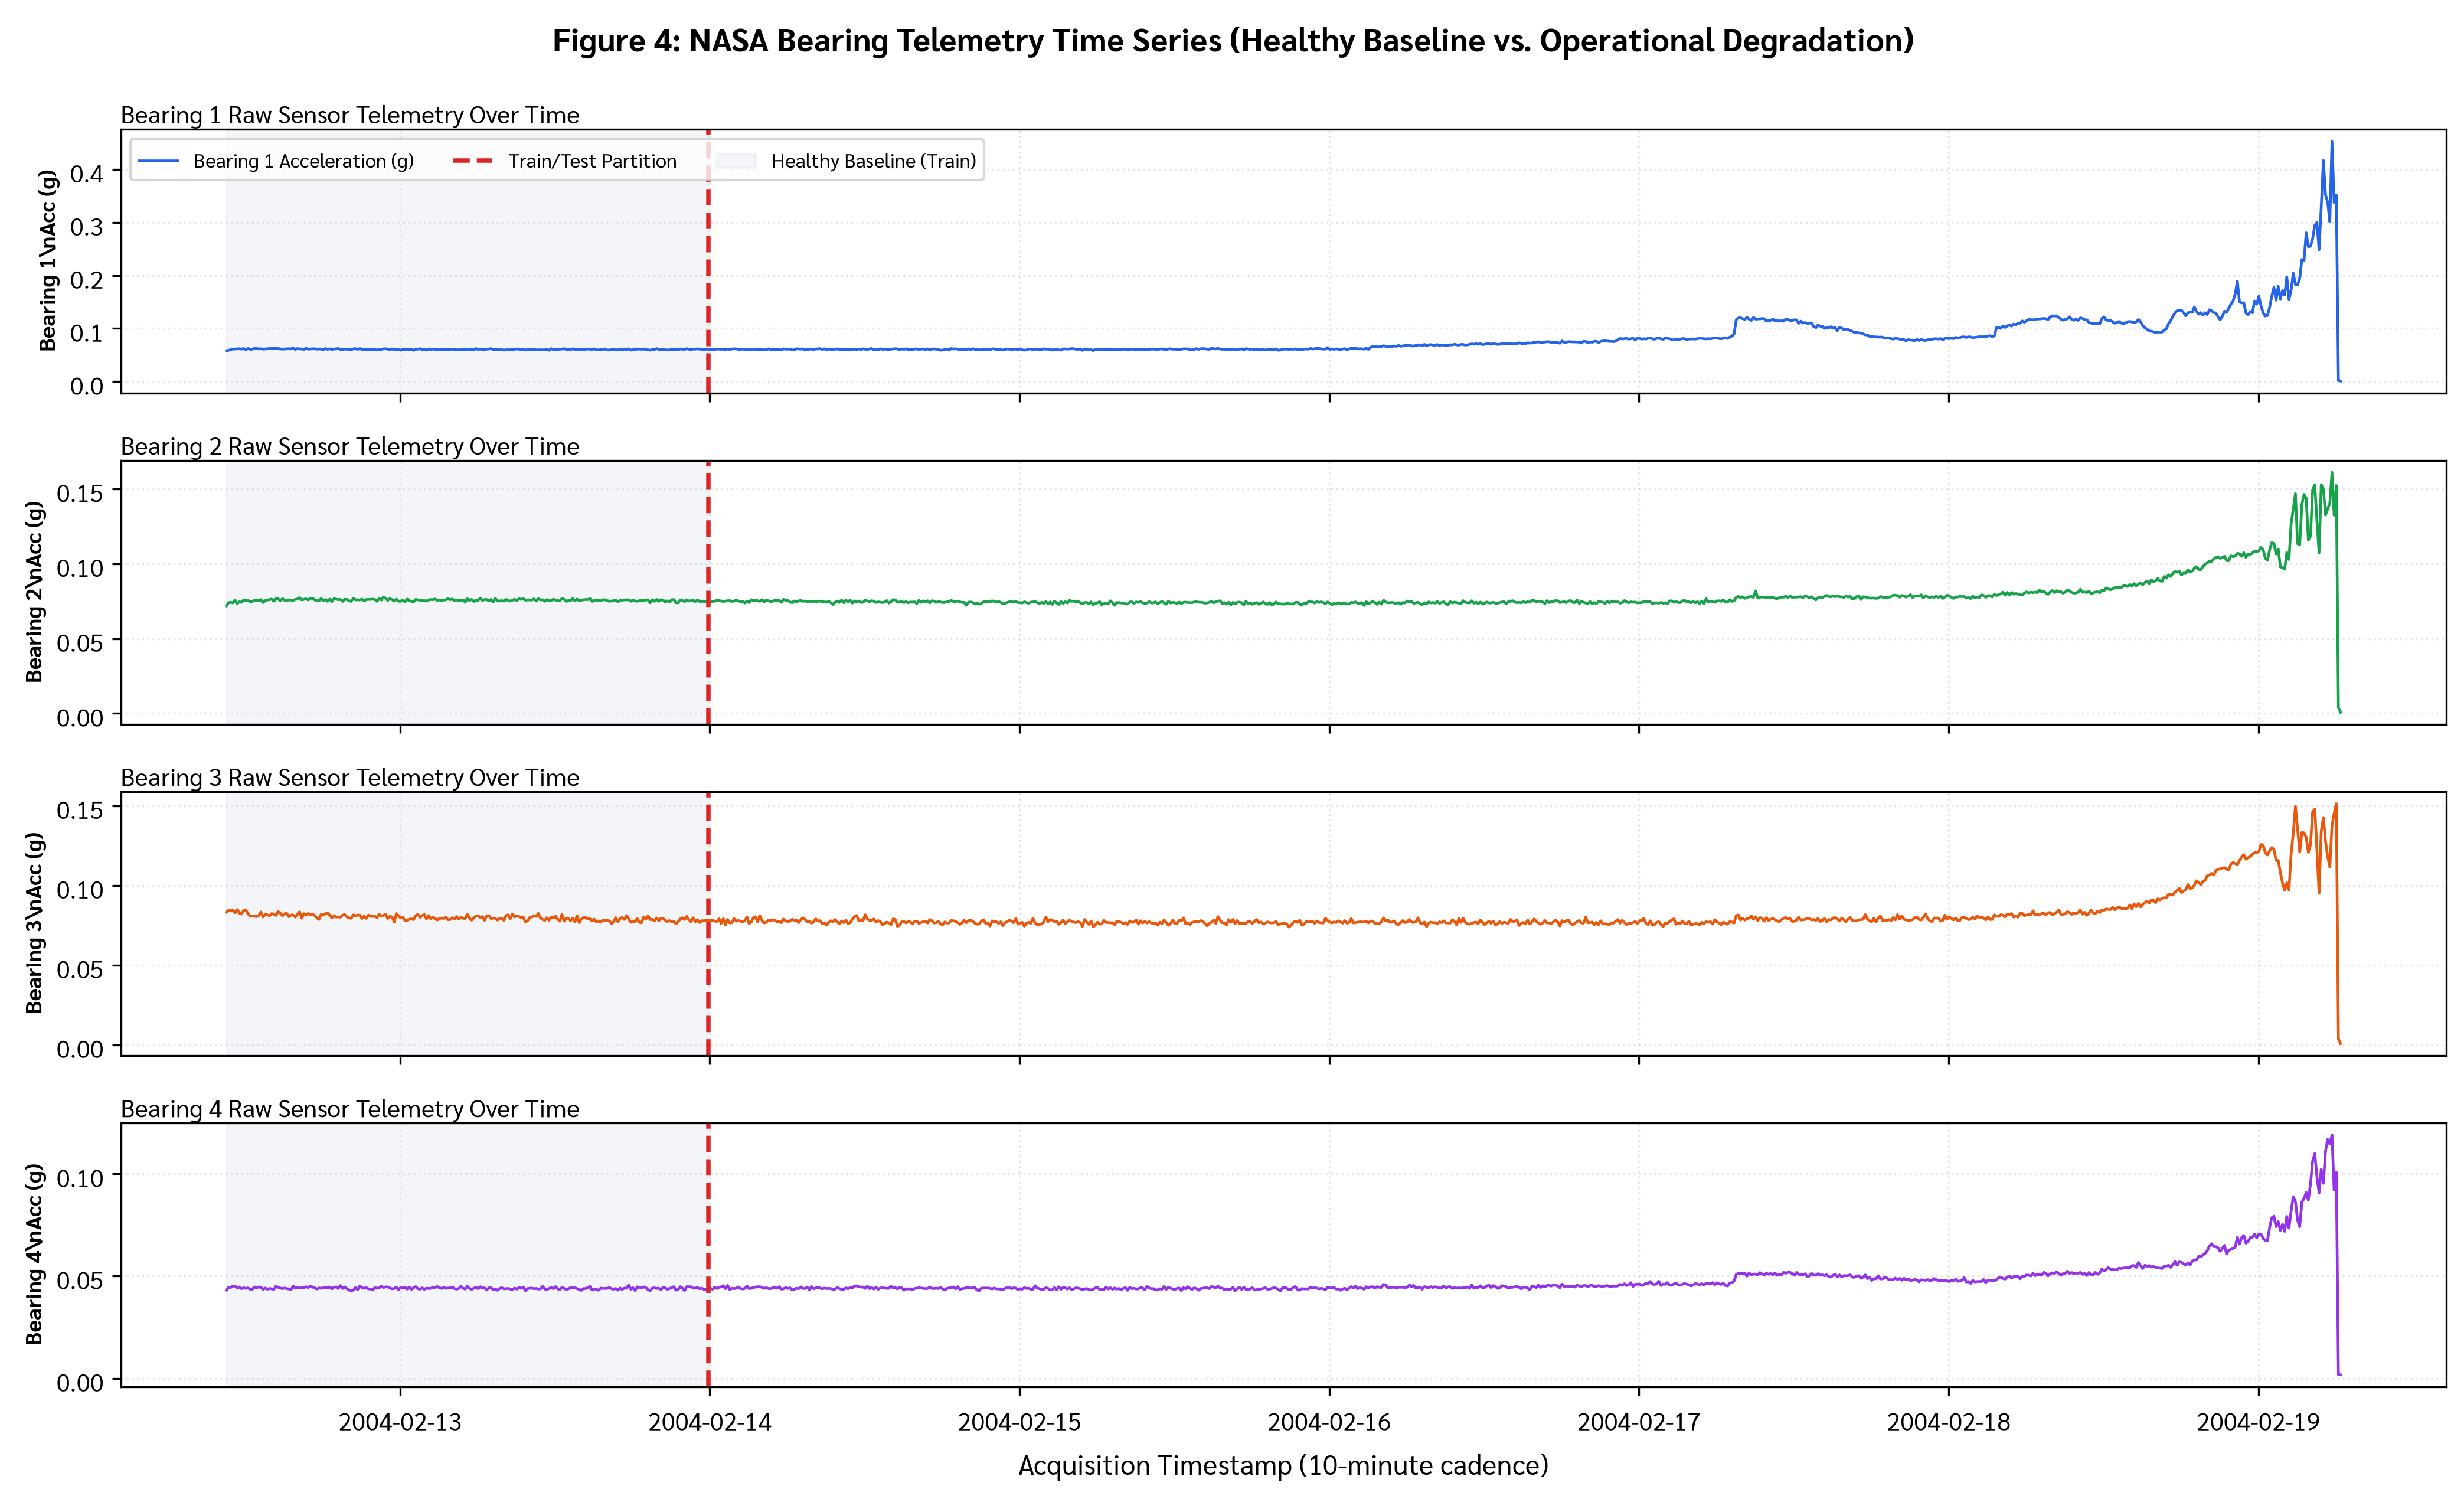

In [12]:
# =========================================================================
# Step 12: Multi-Channel Raw Telemetry Visualization
# =========================================================================
fig, axes = plt.subplots(4, 1, figsize=(14, 8.5), sharex=True)
channel_colors = ['#2563EB', '#16A34A', '#EA580C', '#9333EA']
split_timestamp = pd.to_datetime(train_end)

for i, col in enumerate(bearing_channels):
    ax = axes[i]
    ax.plot(df_bearing.index, df_bearing[col], color=channel_colors[i], lw=1.1, label=f"{col} Acceleration (g)")
    ax.axvline(split_timestamp, color='#DC2626', linestyle='--', lw=1.8, label="Train/Test Partition")
    ax.axvspan(df_bearing.index.min(), split_timestamp, color='#E2E8F0', alpha=0.4, label="Healthy Baseline (Train)")
    ax.set_ylabel(f"{col}\\nAcc (g)", fontsize=9, fontweight='bold')
    if i == 0:
        ax.legend(loc='upper left', frameon=True, fontsize=8, ncol=3)
    ax.set_title(f"{col} Raw Sensor Telemetry Over Time", fontsize=10, loc='left', pad=2)

axes[-1].set_xlabel("Acquisition Timestamp (10-minute cadence)", fontsize=11)
plt.suptitle("Figure 4: NASA Bearing Telemetry Time Series (Healthy Baseline vs. Operational Degradation)", fontsize=13, fontweight='bold', y=0.99)
plt.tight_layout()
plt.savefig('plot_4_bearing_raw_sensor_timeseries.pdf', bbox_inches='tight')
plt.show()

**Standardize the train set and apply the scaler to the test set**

In [13]:
# =========================================================================
# Step 13: Feature Standardization (Zero-Leakage Architecture)
# =========================================================================
# Fit StandardScaler strictly on the nominal training baseline
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(df_train)
X_test_scaled = scaler.transform(df_test)

scaler_summary = pd.DataFrame({
    'Sensor Channel': bearing_channels,
    'Baseline Mean (mu)': scaler.mean_,
    'Baseline Std (sigma)': scaler.scale_
})
print("=== Baseline Standardization Parameters ===")
scaler_summary

=== Baseline Standardization Parameters ===


,Sensor Channel,Baseline Mean (mu),Baseline Std (sigma)
0,Bearing 1,0.060870,0.000832
1,Bearing 2,0.075605,0.000709
2,Bearing 3,0.079808,0.001737
3,Bearing 4,0.044065,0.000525


## PCA Model Construction

**Apply PCA with two components to the train data to obtain the train PC scores**

=== Principal Component Decomposition Summary ===
 - PC 1 Explained Variance : 49.86%
 - PC 2 Explained Variance : 19.51%
 - Cumulative Retained PVE : 69.37% (Compression: 4 -> 2 Dimensions)


Text(0.0, 50.861615145130465, '49.9%')

Text(1.0, 20.506944857224823, '19.5%')

Text(2.0, 18.399976643652888, '17.4%')

Text(3.0, 14.231463353991826, '13.2%')

Text(0.5, 1.0, 'Scree Plot: Percentage of Explained Variance')

Text(0, 0.5, 'Explained Variance (%)')

(0.0, 110.0)

<Axes: >

Text(0.5, 1.0, 'Principal Component Loadings (W in R^{4x2})')

Text(0.5, 1.02, 'Figure 5: Principal Component Subspace Decomposition on Healthy Baseline')

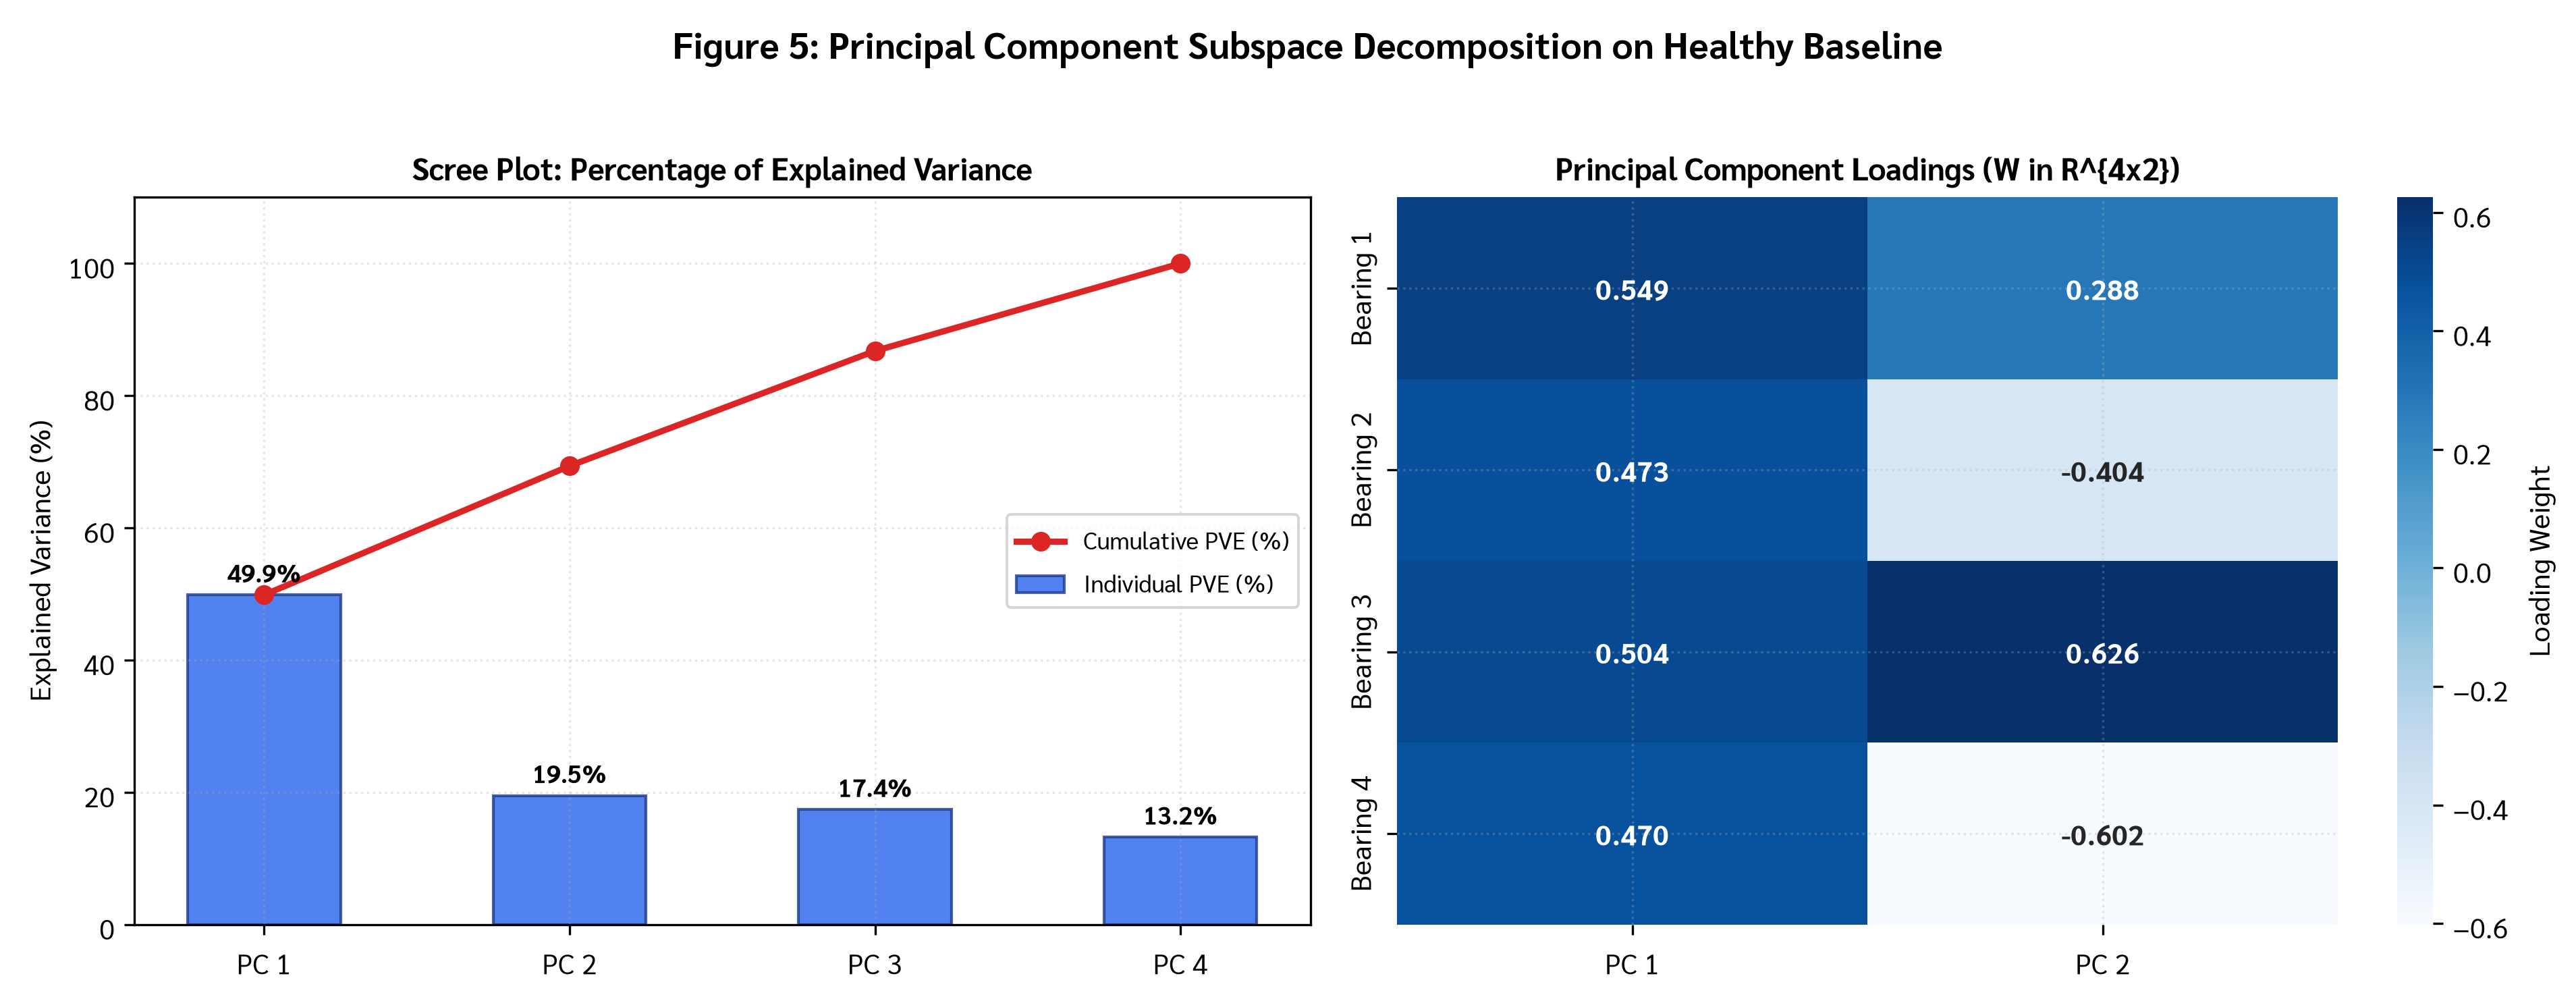

In [14]:
# =========================================================================
# Step 14: Fit Principal Component Subspace (k = 2) on Healthy Baseline
# =========================================================================
pca_model = PCA(n_components=2, random_state=SEED)
PC_train = pca_model.fit_transform(X_train_scaled)

evr = pca_model.explained_variance_ratio_
cum_evr = np.sum(evr)

print("=== Principal Component Decomposition Summary ===")
print(f" - PC 1 Explained Variance : {evr[0] * 100:.2f}%")
print(f" - PC 2 Explained Variance : {evr[1] * 100:.2f}%")
print(f" - Cumulative Retained PVE : {cum_evr * 100:.2f}% (Compression: 4 -> 2 Dimensions)")

# Render Figure 5: Scree Plot & PCA Loadings Heatmap
fig, (ax_scree, ax_load) = plt.subplots(1, 2, figsize=(13, 4.8))

full_pca = PCA().fit(X_train_scaled)
all_evr = full_pca.explained_variance_ratio_ * 100
pcs = [f"PC {i+1}" for i in range(len(all_evr))]

bars = ax_scree.bar(pcs, all_evr, color='#2563EB', width=0.5, alpha=0.8, edgecolor='#1E3A8A', label='Individual PVE (%)')
ax_scree.plot(pcs, np.cumsum(all_evr), color='#DC2626', marker='o', lw=2.2, label='Cumulative PVE (%)')
for b, val in zip(bars, all_evr):
    ax_scree.text(b.get_x() + b.get_width()/2, b.get_height() + 1.0, f"{val:.1f}%", ha='center', va='bottom', fontsize=9, fontweight='bold')
ax_scree.set_title("Scree Plot: Percentage of Explained Variance", fontsize=11, fontweight='bold')
ax_scree.set_ylabel("Explained Variance (%)", fontsize=10)
ax_scree.set_ylim(0, 110)
ax_scree.legend(frameon=True, loc='center right', fontsize=8.5)

loadings_df = pd.DataFrame(pca_model.components_.T, index=bearing_channels, columns=['PC 1', 'PC 2'])
sns.heatmap(loadings_df, annot=True, fmt='.3f', cmap='Blues', ax=ax_load, cbar_kws={'label': 'Loading Weight'},
            annot_kws={'fontsize': 10, 'fontweight': 'bold'})
ax_load.set_title("Principal Component Loadings (W in R^{4x2})", fontsize=11, fontweight='bold')

plt.suptitle("Figure 5: Principal Component Subspace Decomposition on Healthy Baseline", fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('plot_5_bearing_pca_variance_loadings.pdf', bbox_inches='tight')
plt.show()

**Use the PCA model to transform the test data to obtain the test PC scores**

In [15]:
# =========================================================================
# Step 15: Project Operational Test Telemetry into Latent Subspace
# =========================================================================
PC_test = pca_model.transform(X_test_scaled)
print(f"[INFO] Train Latent Projections (PC_train) : {PC_train.shape}")
print(f"[INFO] Test Latent Projections (PC_test)   : {PC_test.shape}")

[INFO] Train Latent Projections (PC_train) : (222, 2)
[INFO] Test Latent Projections (PC_test)   : (759, 2)


## Anomaly Detection with MHD

**Determine squared MHD of train PC scores**

In [16]:
# =========================================================================
# Step 16: Compute Squared MHD on Train Latent Scores (Hotelling's T^2)
# =========================================================================
mu_pc = np.mean(PC_train, axis=0)
cov_pc = np.cov(PC_train, rowvar=False)

# Compute squared MHD on train PC scores
mhd2_train_pc = MHD(PC_train, mu_pc, cov_pc, return_squared=True)
df_train['mhd2_pc'] = mhd2_train_pc

print("=== Latent Principal Component Moments ===")
print(f" - Train Centroid (mu_pc) : [{mu_pc[0]:.6f}, {mu_pc[1]:.6f}]")
print(f" - Train Covariance Matrix Sigma_pc:\n{pd.DataFrame(cov_pc, index=['PC1', 'PC2'], columns=['PC1', 'PC2']).round(6)}")
print(f"\nTrain Latent D_M^2 Mean : {mhd2_train_pc.mean():.4f} (Expected df=2: 2.000)")
print(f"Train Latent D_M^2 Max  : {mhd2_train_pc.max():.4f}")

=== Latent Principal Component Moments ===
 - Train Centroid (mu_pc) : [0.000000, -0.000000]
 - Train Covariance Matrix Sigma_pc:
          PC1       PC2
PC1  2.003489  0.000000
PC2  0.000000  0.783808

Train Latent D_M^2 Mean : 1.9910 (Expected df=2: 2.000)
Train Latent D_M^2 Max  : 14.0776


**Visualize the histogram of squared MHD of the train PC scores**

<Axes: ylabel='Density'>

Text(0.5, 1.0, 'Histogram of Squared MHD on Train PC Scores vs. $\\chi^2(df=2)$')

Text(0.5, 0, 'Latent Squared Mahalanobis Distance $D_M^2$ ($T^2$ Statistic)')

Text(0, 0.5, 'Probability Density')

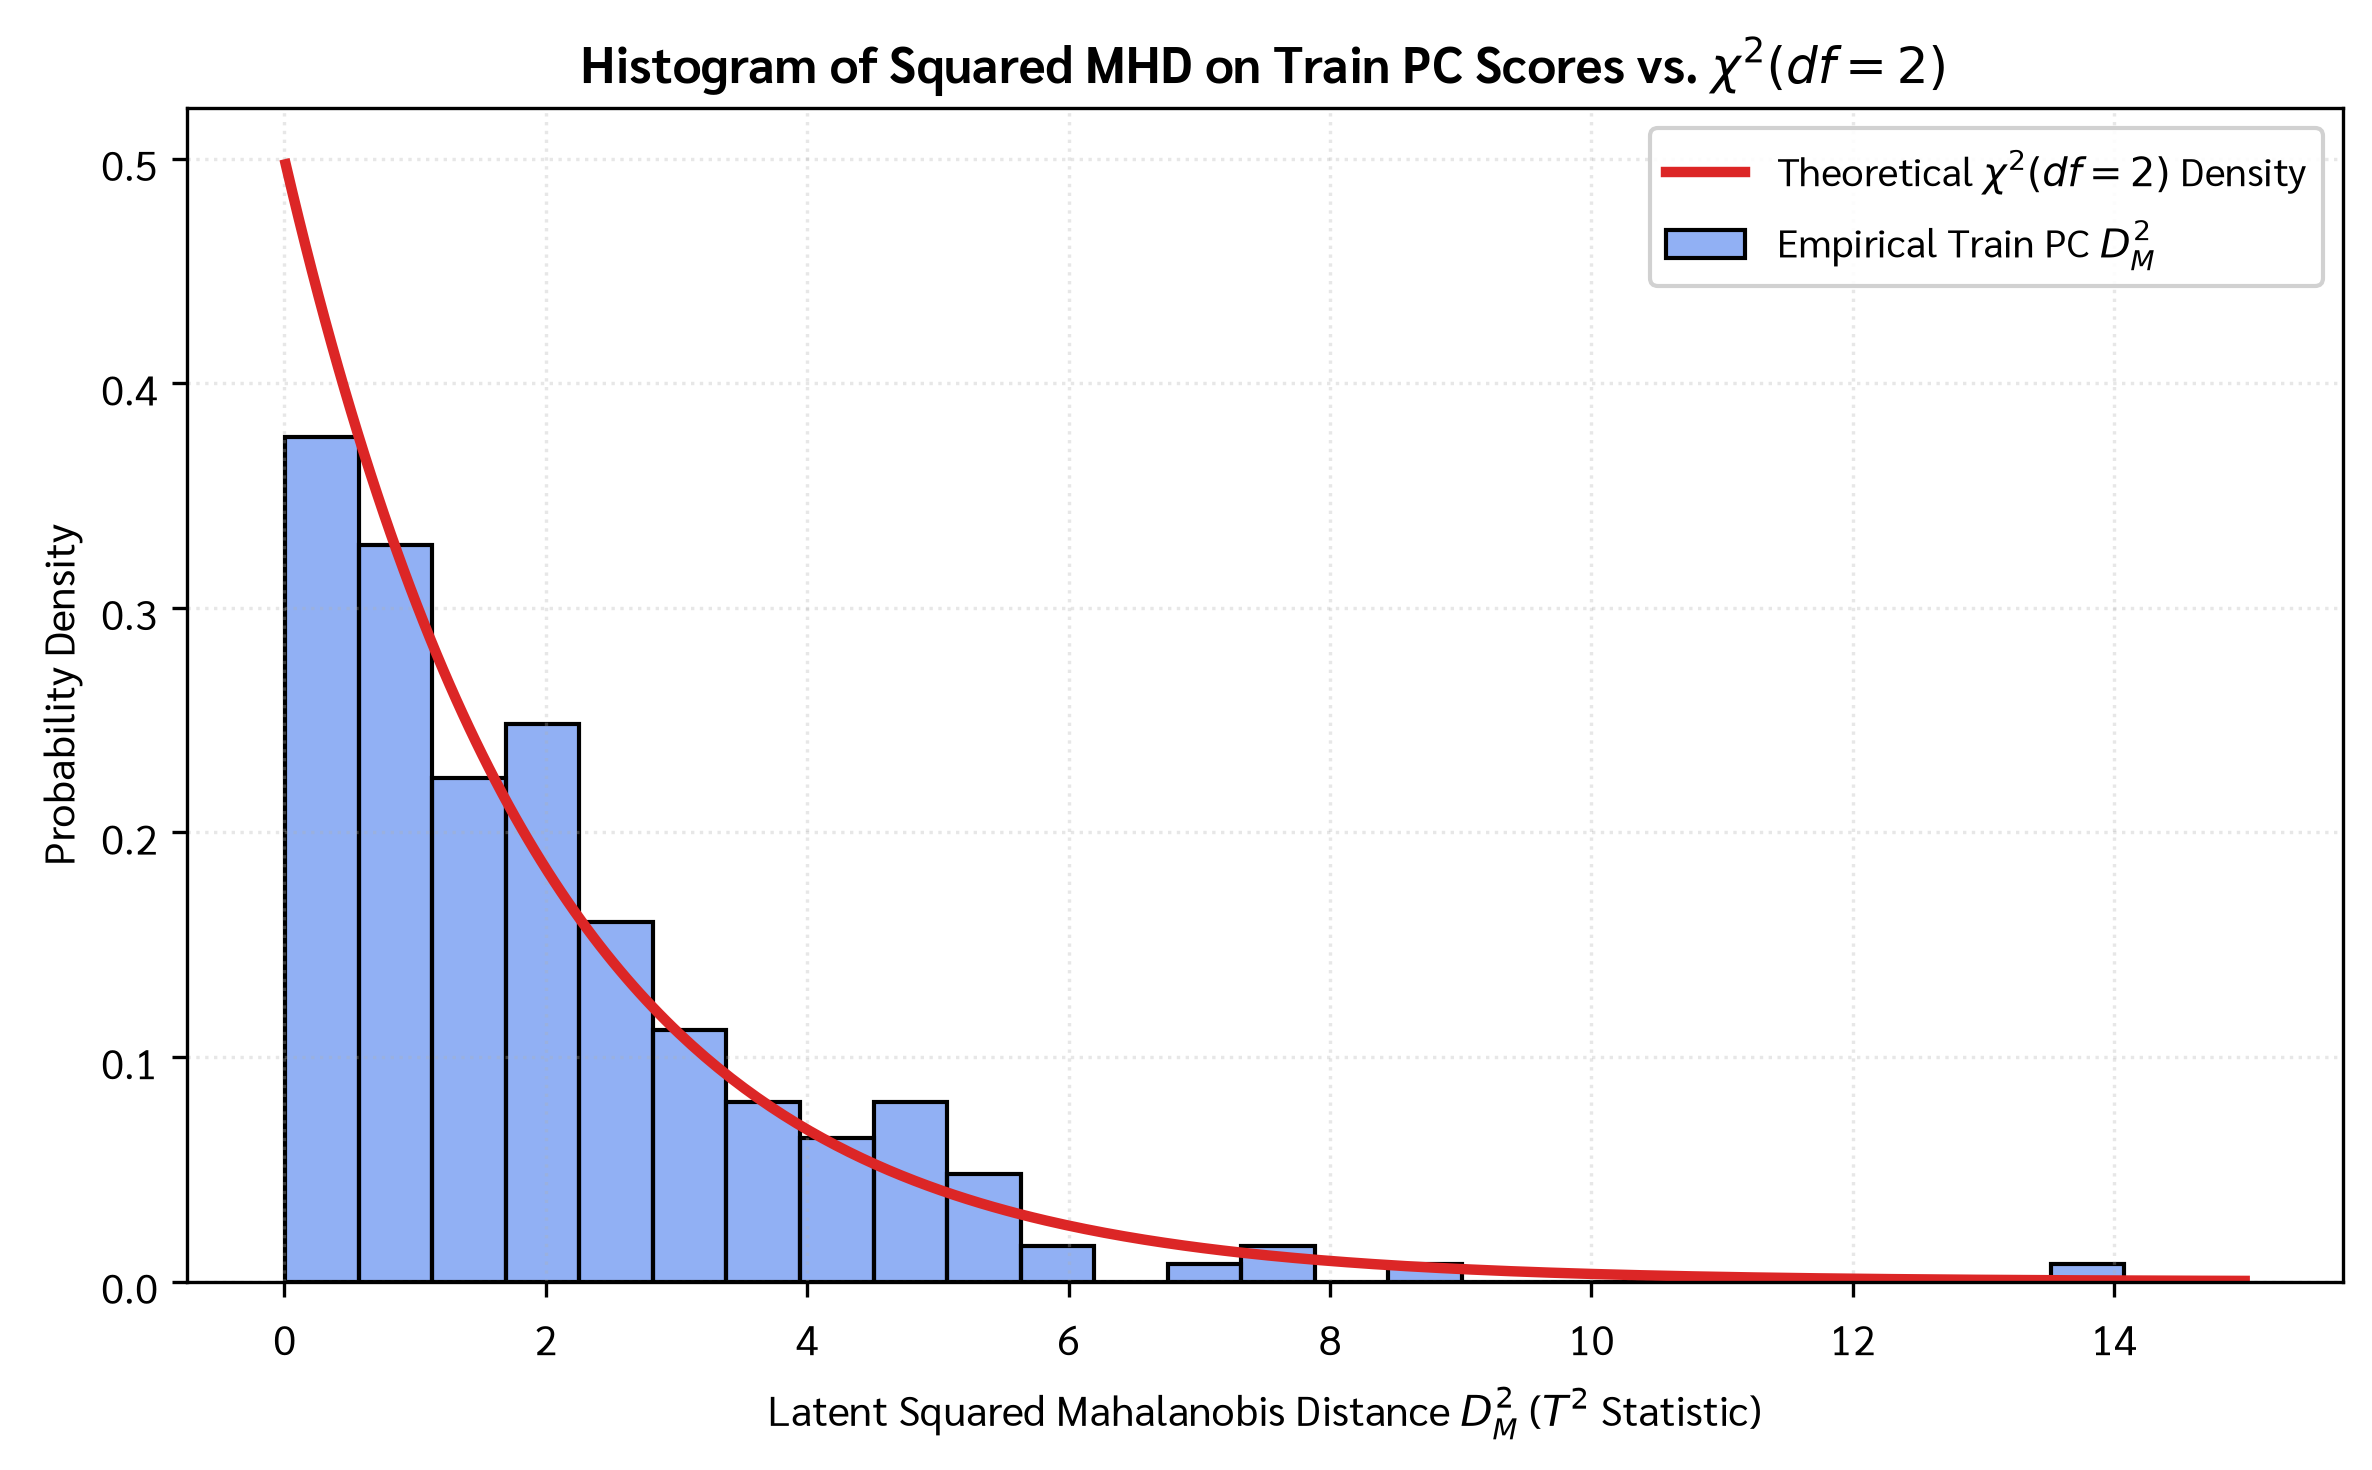

In [17]:
# =========================================================================
# Step 17: Histogram of Train PC Squared MHD vs Theoretical Chi2(2)
# =========================================================================
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(mhd2_train_pc, stat='density', bins=25, color='#2563EB', alpha=0.5, label='Empirical Train PC $D_M^2$', ax=ax)

# Theoretical Chi-square with df = 2 (exponential distribution)
x_pc = np.linspace(0.01, 15, 300)
pdf_chi2_pc = stats.chi2.pdf(x_pc, df=2)
ax.plot(x_pc, pdf_chi2_pc, color='#DC2626', lw=2.5, label=r'Theoretical $\chi^2(df=2)$ Density')

ax.set_title(r"Histogram of Squared MHD on Train PC Scores vs. $\chi^2(df=2)$", fontsize=12, fontweight='bold')
ax.set_xlabel(r"Latent Squared Mahalanobis Distance $D_M^2$ ($T^2$ Statistic)", fontsize=10)
ax.set_ylabel("Probability Density", fontsize=10)
ax.legend(frameon=True, facecolor='white', framealpha=0.9, fontsize=9.5)
plt.tight_layout()
plt.show()

**Set the outlier threshold**

If the data is approximately multivariate normal, the squared Mahalanobis distance will be  
approximately $\\chi^2$ with df = # of variables. Let's use the critical value at 0.001 as the outlier threshold.

In [18]:
# =========================================================================
# Step 18: Latent Outlier Threshold at alpha = 0.001 (df = 2)
# =========================================================================
alpha_bearing = 0.001
df_pc_dim = 2

threshold_pc_001 = float(stats.chi2.isf(alpha_bearing, df=df_pc_dim))
print("=== Latent Anomaly Gating Threshold ===")
print(f" - Degrees of Freedom (df)    : {df_pc_dim} Principal Components")
print(f" - Significance Level (alpha) : {alpha_bearing} (99.9% Inlier Region)")
print(f" - Critical Cutoff Chi^2_0.001: {threshold_pc_001:.4f}")

=== Latent Anomaly Gating Threshold ===
 - Degrees of Freedom (df)    : 2 Principal Components
 - Significance Level (alpha) : 0.001 (99.9% Inlier Region)
 - Critical Cutoff Chi^2_0.001: 13.8155


**Determine squared MHD of test PC scores**

In [19]:
# =========================================================================
# Step 19: Compute Latent Squared MHD on Operational Test Telemetry
# =========================================================================
mhd2_test_pc = MHD(PC_test, mu_pc, cov_pc, return_squared=True)
df_test['mhd2_pc'] = mhd2_test_pc

print(f"[INFO] Computed Test Latent Squared MHD across {len(df_test)} test observations.")
print(f" - Test D_M^2 Minimum : {mhd2_test_pc.min():.4f}")
print(f" - Test D_M^2 Median  : {np.median(mhd2_test_pc):.4f}")
print(f" - Test D_M^2 Maximum : {mhd2_test_pc.max():.4f}")

[INFO] Computed Test Latent Squared MHD across 759 test observations.
 - Test D_M^2 Minimum : 0.0092
 - Test D_M^2 Median  : 31.6356
 - Test D_M^2 Maximum : 80465.1731


**Visualize the squared MHD of train and test PC against the threshold**.

From the plot, approximately at what datetime the model detects the equipment failure?

=== Latent MHD (Hotelling's T^2) Anomaly Detection Result ===
Critical Outlier Threshold  : 13.8155
First Anomaly Timestamp     : 2004-02-15 04:52:39
First Anomalous MHD^2 Score : 14.2035
Total Anomalous Snapshots   : 420 / 759 (55.3%)


Text(2004-02-13 04:52:39, 1514.203538870759, 'First Anomaly Detected:\\n2004-02-15 04:52:39\\n($D_M^2 = 14.20$)')

Text(0.5, 1.0, 'Figure 6: Latent-Variable Mahalanobis Distance ($T^2$) Anomaly Detection Timeline')

Text(0.5, 0, 'Acquisition Timestamp')

Text(0, 0.5, 'Squared Mahalanobis Distance $D_M^2$ (Log Scale)')

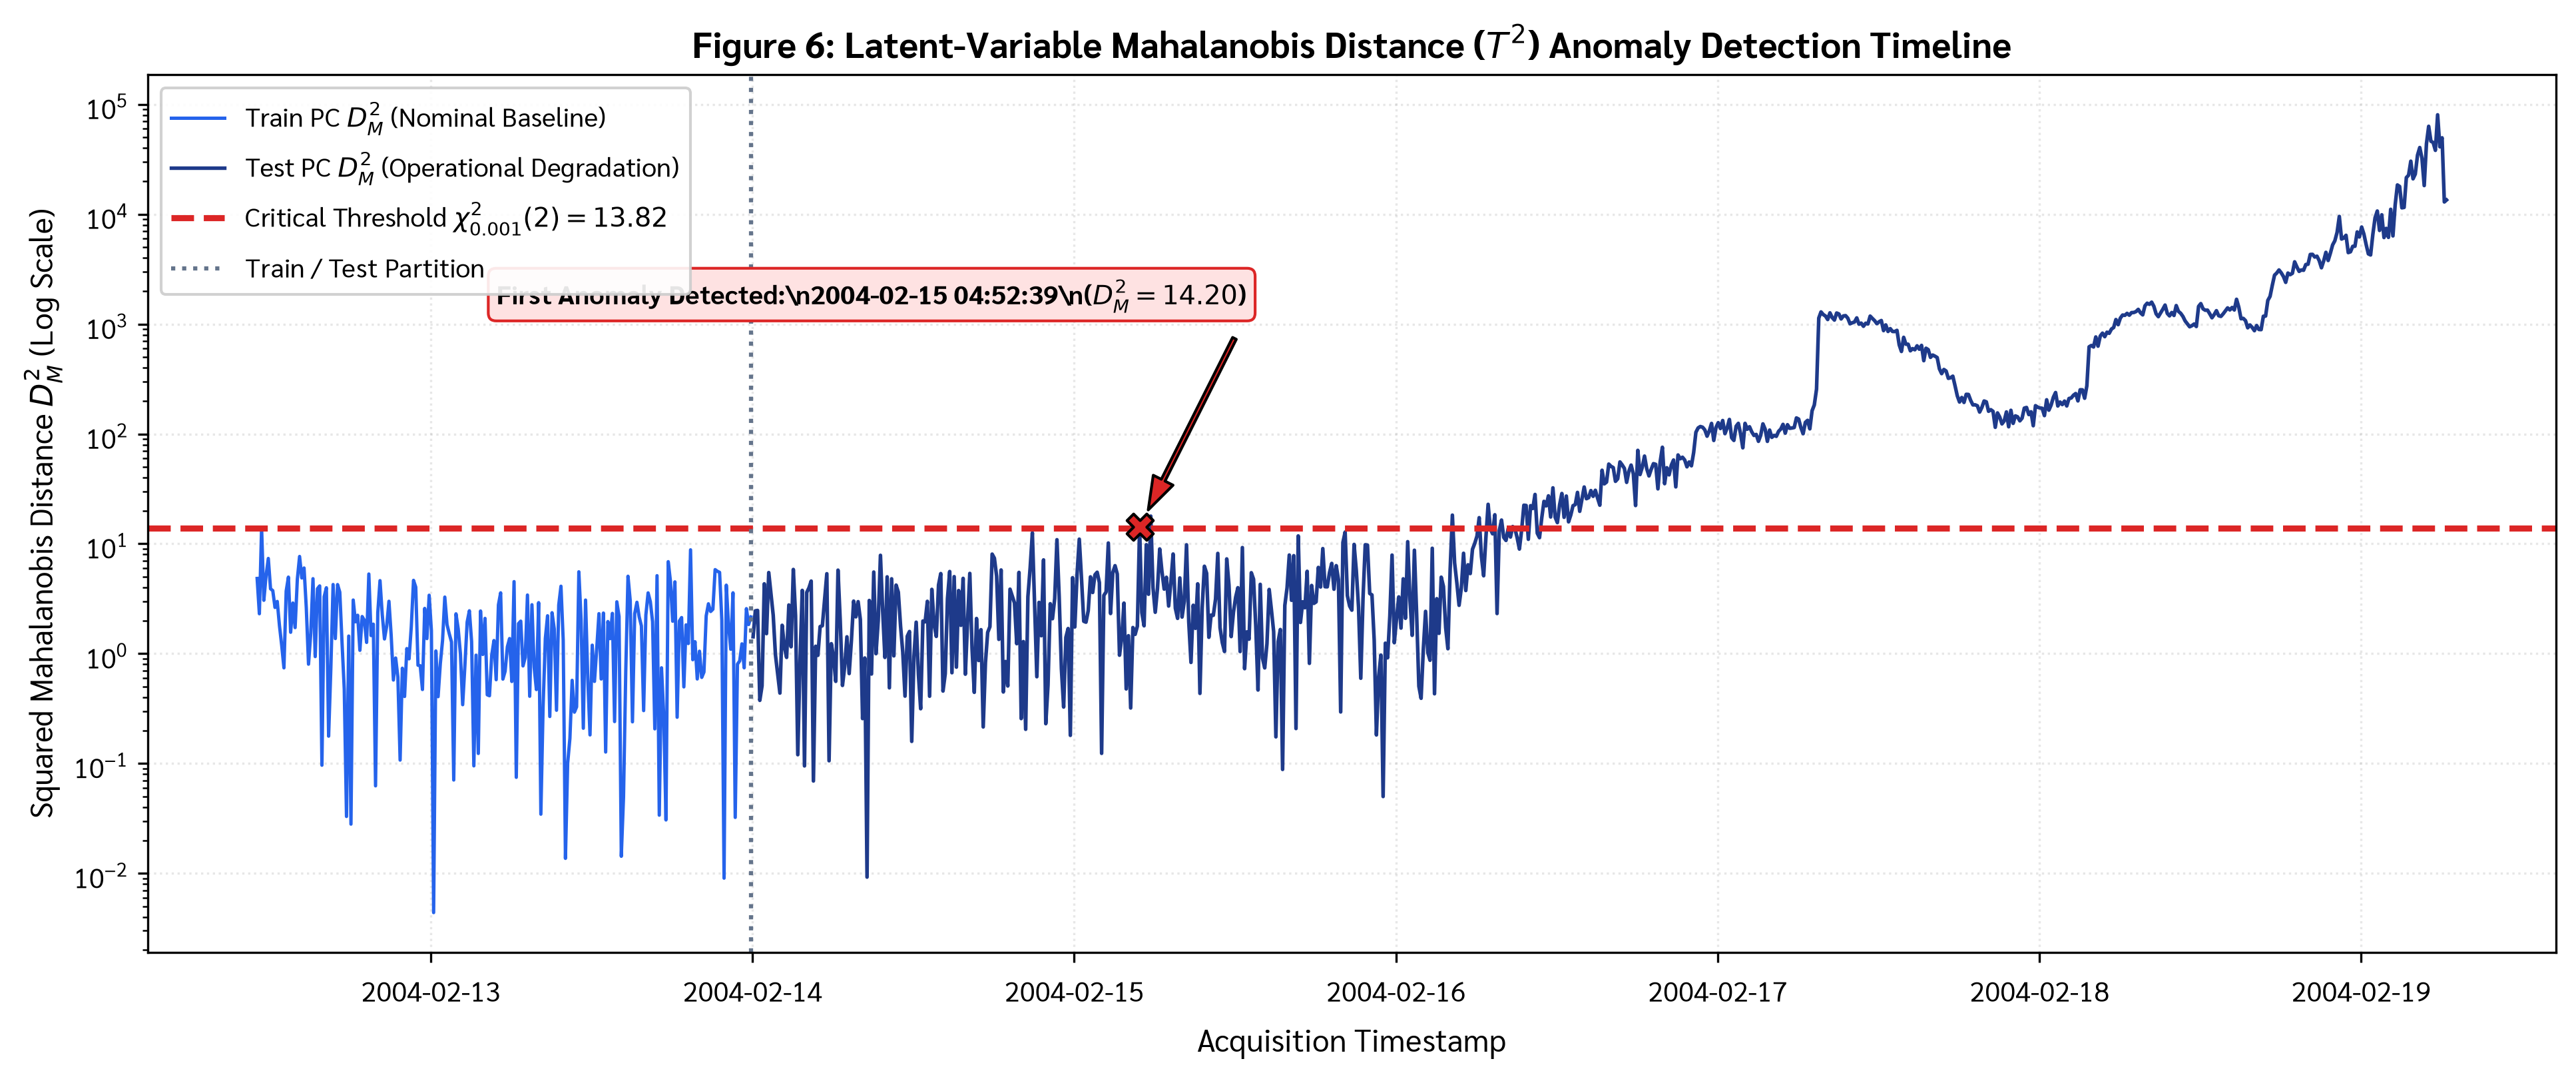

In [20]:
# =========================================================================
# Step 20: Latent Space Anomaly Timeline & Equipment Failure Onset
# =========================================================================
s_test_mhd = df_test['mhd2_pc']
anomalous_mhd_snapshots = s_test_mhd[s_test_mhd > threshold_pc_001]
mhd_onset_timestamp = anomalous_mhd_snapshots.index[0]
mhd_onset_score = anomalous_mhd_snapshots.iloc[0]

print("=== Latent MHD (Hotelling's T^2) Anomaly Detection Result ===")
print(f"Critical Outlier Threshold  : {threshold_pc_001:.4f}")
print(f"First Anomaly Timestamp     : {mhd_onset_timestamp}")
print(f"First Anomalous MHD^2 Score : {mhd_onset_score:.4f}")
print(f"Total Anomalous Snapshots   : {len(anomalous_mhd_snapshots)} / {len(df_test)} ({len(anomalous_mhd_snapshots)/len(df_test)*100:.1f}%)")

# Render Figure 6: Latent MHD Timeline Plot
fig, ax = plt.subplots(figsize=(13, 5.5))
ax.plot(df_train.index, df_train['mhd2_pc'], color='#2563EB', lw=1.2, label='Train PC $D_M^2$ (Nominal Baseline)')
ax.plot(df_test.index, df_test['mhd2_pc'], color='#1E3A8A', lw=1.3, label='Test PC $D_M^2$ (Operational Degradation)')
ax.axhline(threshold_pc_001, color='#DC2626', linestyle='--', lw=2.2, label=rf'Critical Threshold $\chi^2_{{0.001}}(2) = {threshold_pc_001:.2f}$')

ax.scatter([mhd_onset_timestamp], [mhd_onset_score], color='#DC2626', s=90, zorder=5, edgecolor='black', marker='X')
ax.annotate(f"First Anomaly Detected:\\n{mhd_onset_timestamp}\\n($D_M^2 = {mhd_onset_score:.2f}$)",
            xy=(mhd_onset_timestamp, mhd_onset_score),
            xytext=(mhd_onset_timestamp - pd.Timedelta(hours=48), mhd_onset_score + 1500),
            arrowprops=dict(facecolor='#DC2626', shrink=0.08, width=1.5, headwidth=8),
            fontsize=9.5, fontweight='bold', bbox=dict(boxstyle='round,pad=0.3', facecolor='#FEE2E2', edgecolor='#DC2626'))

ax.axvline(pd.to_datetime(train_end), color='#64748B', linestyle=':', lw=1.5, label='Train / Test Partition')
ax.set_yscale('log')
ax.set_title(r"Figure 6: Latent-Variable Mahalanobis Distance ($T^2$) Anomaly Detection Timeline", fontsize=13, fontweight='bold')
ax.set_xlabel("Acquisition Timestamp", fontsize=11)
ax.set_ylabel(r"Squared Mahalanobis Distance $D_M^2$ (Log Scale)", fontsize=11)
ax.legend(frameon=True, facecolor='white', framealpha=0.9, fontsize=9.5, loc='upper left')
plt.tight_layout()
plt.savefig('plot_6_bearing_mhd_latent_scores.pdf', bbox_inches='tight')
plt.show()

## Anomaly Detection with Reconstruction Errors 

In this approach, the inversed transform of PC scores are compared to the original data and the reconstruction errors are determined.  
The Mean Absolute Error (MAE) metric will be used to measure the reconstruction errors, which are the outlier scores of data points.  
The outlier threshold is derived based on the MAE of train data.

Determine the inverse-transform of the train PC scores.
Then, compute the MAE of the reconstructed data and the train data.

In [21]:
# =========================================================================
# Step 21: Inverse Transformation & Training Reconstruction Error (MAE)
# =========================================================================
# Inverse project latent PC scores back to standardized physical sensor space
X_train_rec = pca_model.inverse_transform(PC_train)

# Calculate sample-wise Mean Absolute Error (MAE) across all 4 sensor channels
mae_train = np.mean(np.abs(X_train_scaled - X_train_rec), axis=1)
df_train['mae'] = mae_train

print("=== Training Reconstruction Error (MAE) Summary ===")
print(f" - Train MAE Minimum : {mae_train.min():.5f}")
print(f" - Train MAE Median  : {np.median(mae_train):.5f}")
print(f" - Train MAE Mean    : {mae_train.mean():.5f}")
print(f" - Train MAE Maximum : {mae_train.max():.5f}")

=== Training Reconstruction Error (MAE) Summary ===
 - Train MAE Minimum : 0.02311
 - Train MAE Median  : 0.40030
 - Train MAE Mean    : 0.43165
 - Train MAE Maximum : 1.55557


Plot the MAE of the reconstructed data and the train data.

<Axes: ylabel='Count'>

Text(0.5, 1.0, 'Distribution of Training Reconstruction Error (MAE)')

Text(0.5, 0, 'Reconstruction Error MAE')

Text(0, 0.5, 'Frequency')

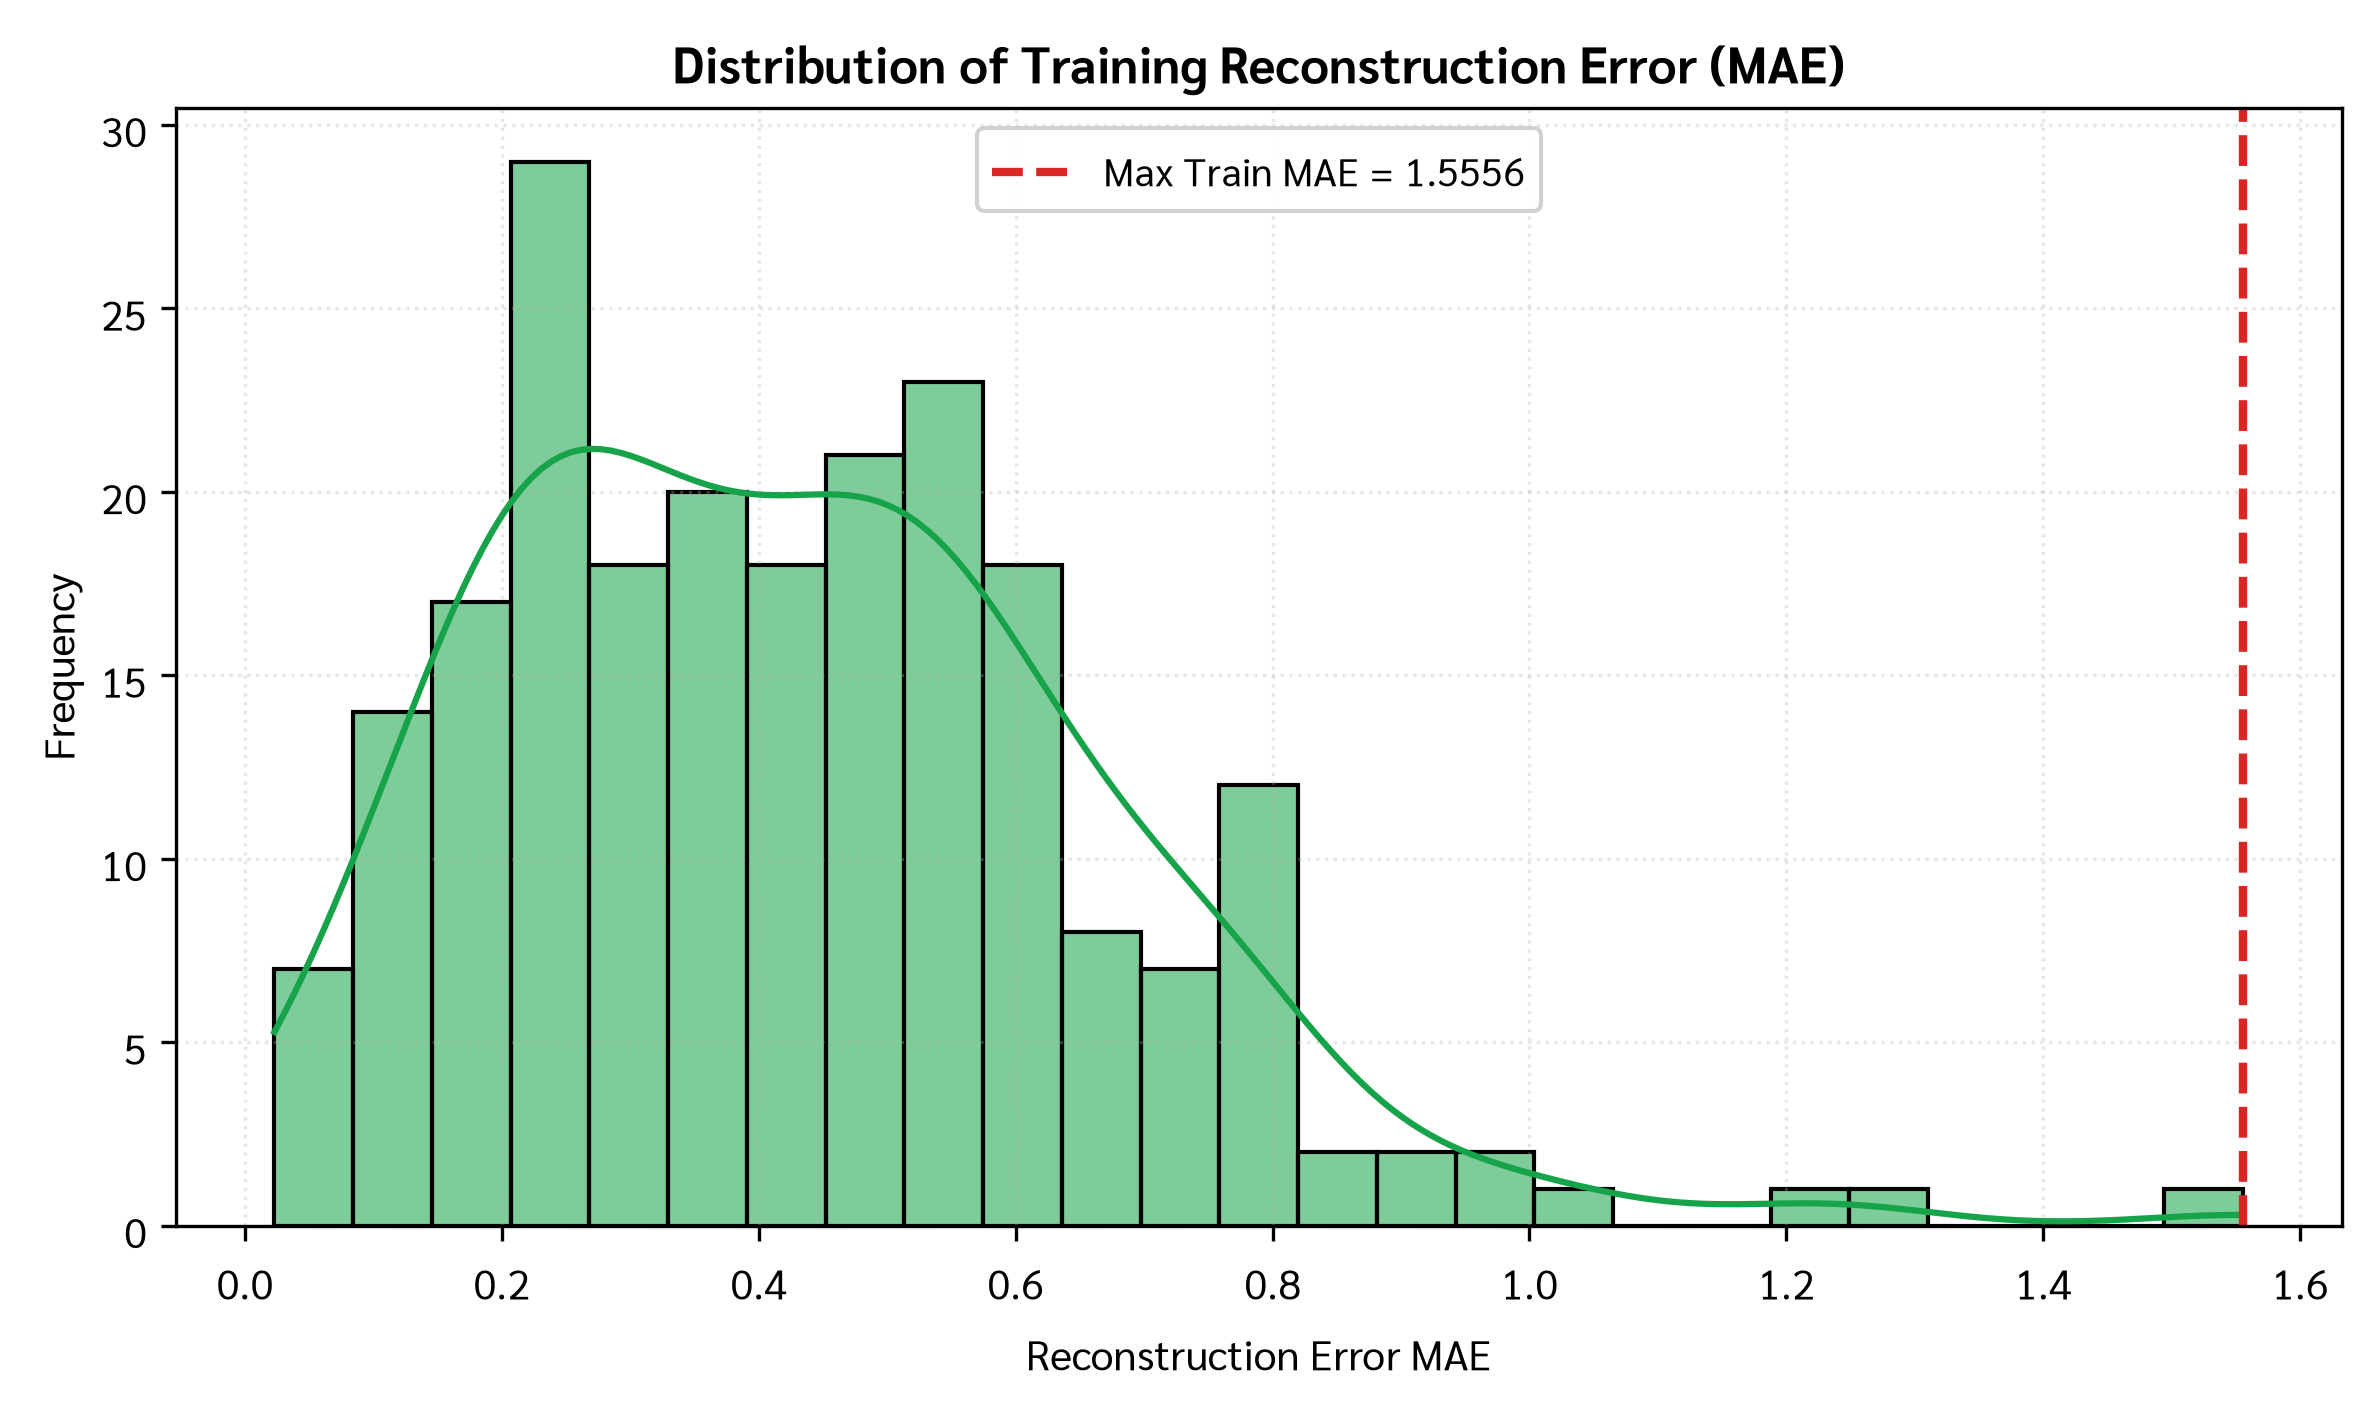

In [22]:
# =========================================================================
# Step 22: Visualize Training Reconstruction MAE Distribution
# =========================================================================
fig, ax = plt.subplots(figsize=(8, 4.8))
sns.histplot(mae_train, kde=True, bins=25, color='#16A34A', alpha=0.55, ax=ax)
ax.axvline(mae_train.max(), color='#DC2626', linestyle='--', lw=2.0, label=f"Max Train MAE = {mae_train.max():.4f}")
ax.set_title("Distribution of Training Reconstruction Error (MAE)", fontsize=12, fontweight='bold')
ax.set_xlabel("Reconstruction Error MAE", fontsize=10)
ax.set_ylabel("Frequency", fontsize=10)
ax.legend(frameon=True, facecolor='white', framealpha=0.9, fontsize=9.5)
plt.tight_layout()
plt.show()

Set the outlier threshold as 110% of the maximum MAE.

In [23]:
# =========================================================================
# Step 23: Determine Reconstruction Anomaly Gating Thresholds
# =========================================================================
mae_max_train = float(mae_train.max())

# Primary threshold specified in Cell 48 (110% of max MAE)
threshold_mae_110 = 1.10 * mae_max_train

# Alternative threshold specified in Cell 18 (105% of max MAE)
threshold_mae_105 = 1.05 * mae_max_train

print("=== Reconstruction Error Anomaly Thresholds ===")
print(f" - Baseline Max Train MAE            : {mae_max_train:.5f}")
print(f" - 110% Outlier Threshold (Cell 48)  : {threshold_mae_110:.5f}")
print(f" - 105% Outlier Threshold (Cell 18)  : {threshold_mae_105:.5f}")

=== Reconstruction Error Anomaly Thresholds ===
 - Baseline Max Train MAE            : 1.55557
 - 110% Outlier Threshold (Cell 48)  : 1.71113
 - 105% Outlier Threshold (Cell 18)  : 1.63335


**Determine the MAE of test PC data**

In [24]:
# =========================================================================
# Step 24: Reconstruct Operational Test Telemetry & Calculate MAE
# =========================================================================
X_test_rec = pca_model.inverse_transform(PC_test)
mae_test = np.mean(np.abs(X_test_scaled - X_test_rec), axis=1)
df_test['mae'] = mae_test

print("=== Test Telemetry Reconstruction Error (MAE) Summary ===")
print(f" - Test MAE Minimum : {mae_test.min():.5f}")
print(f" - Test MAE Median  : {np.median(mae_test):.5f}")
print(f" - Test MAE Maximum : {mae_test.max():.5f} (Severe Catastrophic Spike)")

=== Test Telemetry Reconstruction Error (MAE) Summary ===
 - Test MAE Minimum : 0.02267
 - Test MAE Median  : 5.10226
 - Test MAE Maximum : 129.87650 (Severe Catastrophic Spike)


**Visualize the MAE of train and test data against the threshold**.

From the plot, approximately at what datetime the model detects the equipment failure?

=== Anomaly Detection & Equipment Failure Onset Findings ===
1) 110% Threshold (1.7111) : First detected at -> 2004-02-15 07:22:39 (MAE = 1.7255)
2) 105% Threshold (1.6334) : First detected at -> 2004-02-14 19:52:39 (MAE = 1.6949)
3) Latent MHD Threshold (13.82) : First detected at -> 2004-02-15 04:52:39 (D_M^2 = 14.20)
4) Peak Catastrophic Failure : 2004-02-19 05:42:39 (MAE = 129.88)
\n[CONCLUSION] The model detects incipient equipment failure on 2004-02-15 07:22:39 (110% threshold)
or 2004-02-14 19:52:39 (105% threshold), providing approximately 94.3 to 105.8 hours
of early warning lead time before catastrophic breakdown on February 19, 2004.


Text(2004-02-12 23:52:39, 30, '105% Crossing:\\n2004-02-14 19:52:39')

Text(2004-02-15 21:22:39, 50, '110% Crossing:\\n2004-02-15 07:22:39')

Text(0.5, 1.0, 'Figure 7: Reconstruction Error (MAE) Anomaly Detection Timeline & Early Warning Tracking')

Text(0.5, 0, 'Acquisition Timestamp')

Text(0, 0.5, 'Reconstruction Error MAE (Log Scale)')

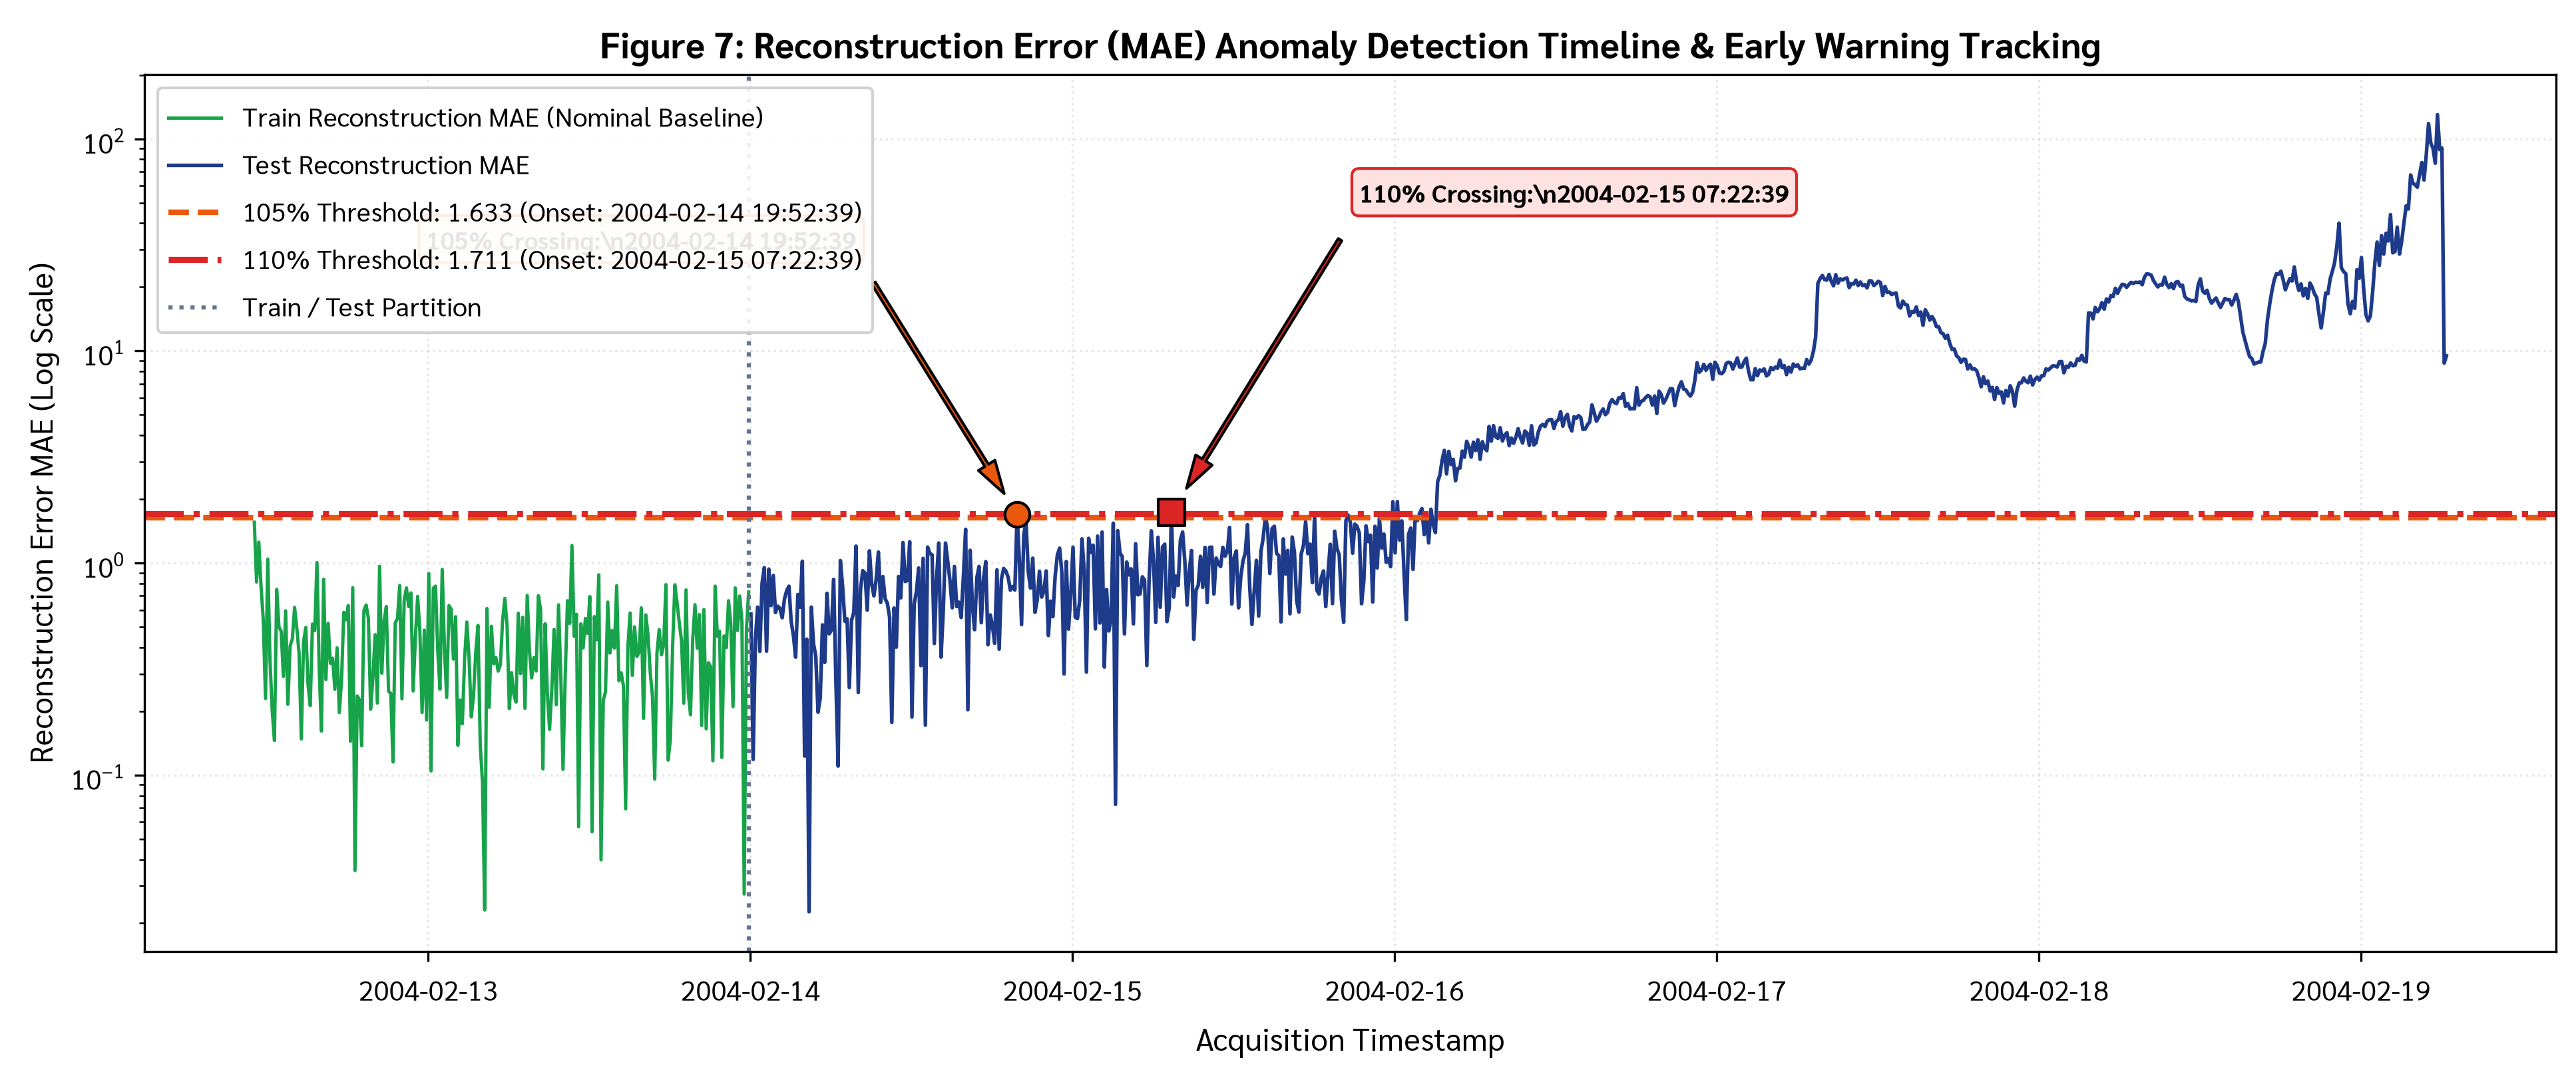

In [25]:
# =========================================================================
# Step 25: Reconstruction Anomaly Timeline & Equipment Failure Identification
# =========================================================================
s_test_mae = df_test['mae']

# 110% Threshold Crossing (Cell 48)
anom_mae_110 = s_test_mae[s_test_mae > threshold_mae_110]
onset_110_timestamp = anom_mae_110.index[0]
onset_110_score = anom_mae_110.iloc[0]

# 105% Threshold Crossing (Cell 18)
anom_mae_105 = s_test_mae[s_test_mae > threshold_mae_105]
onset_105_timestamp = anom_mae_105.index[0]
onset_105_score = anom_mae_105.iloc[0]

# Peak failure timestamp
peak_failure_ts = s_test_mae.idxmax()
peak_failure_val = s_test_mae.max()

print("=== Anomaly Detection & Equipment Failure Onset Findings ===")
print(f"1) 110% Threshold ({threshold_mae_110:.4f}) : First detected at -> {onset_110_timestamp} (MAE = {onset_110_score:.4f})")
print(f"2) 105% Threshold ({threshold_mae_105:.4f}) : First detected at -> {onset_105_timestamp} (MAE = {onset_105_score:.4f})")
print(f"3) Latent MHD Threshold ({threshold_pc_001:.2f}) : First detected at -> {mhd_onset_timestamp} (D_M^2 = {mhd_onset_score:.2f})")
print(f"4) Peak Catastrophic Failure : {peak_failure_ts} (MAE = {peak_failure_val:.2f})")

lead_time_110 = (peak_failure_ts - onset_110_timestamp).total_seconds() / 3600.0
lead_time_105 = (peak_failure_ts - onset_105_timestamp).total_seconds() / 3600.0
print(f"\\n[CONCLUSION] The model detects incipient equipment failure on {onset_110_timestamp.strftime('%Y-%m-%d %H:%M:%S')} (110% threshold)")
print(f"or {onset_105_timestamp.strftime('%Y-%m-%d %H:%M:%S')} (105% threshold), providing approximately {lead_time_110:.1f} to {lead_time_105:.1f} hours")
print("of early warning lead time before catastrophic breakdown on February 19, 2004.")

# Render Figure 7: Reconstruction MAE Timeline Plot
fig, ax = plt.subplots(figsize=(13, 5.5))
ax.plot(df_train.index, df_train['mae'], color='#16A34A', lw=1.2, label='Train Reconstruction MAE (Nominal Baseline)')
ax.plot(df_test.index, df_test['mae'], color='#1E3A8A', lw=1.3, label='Test Reconstruction MAE')
ax.axhline(threshold_mae_105, color='#EA580C', linestyle='--', lw=2.0, label=rf'105% Threshold: {threshold_mae_105:.3f} (Onset: {onset_105_timestamp})')
ax.axhline(threshold_mae_110, color='#DC2626', linestyle='-.', lw=2.2, label=rf'110% Threshold: {threshold_mae_110:.3f} (Onset: {onset_110_timestamp})')

# Annotate onsets
ax.scatter([onset_105_timestamp], [onset_105_score], color='#EA580C', s=80, zorder=5, marker='o', edgecolor='black')
ax.scatter([onset_110_timestamp], [onset_110_score], color='#DC2626', s=90, zorder=5, marker='s', edgecolor='black')

ax.annotate(f"105% Crossing:\\n{onset_105_timestamp}",
            xy=(onset_105_timestamp, onset_105_score),
            xytext=(onset_105_timestamp - pd.Timedelta(hours=44), 30),
            arrowprops=dict(facecolor='#EA580C', shrink=0.08, width=1.5, headwidth=7),
            fontsize=9, fontweight='bold', bbox=dict(boxstyle='round,pad=0.3', facecolor='#FFEDD5', edgecolor='#EA580C'))

ax.annotate(f"110% Crossing:\\n{onset_110_timestamp}",
            xy=(onset_110_timestamp, onset_110_score),
            xytext=(onset_110_timestamp + pd.Timedelta(hours=14), 50),
            arrowprops=dict(facecolor='#DC2626', shrink=0.08, width=1.5, headwidth=7),
            fontsize=9, fontweight='bold', bbox=dict(boxstyle='round,pad=0.3', facecolor='#FEE2E2', edgecolor='#DC2626'))

ax.axvline(pd.to_datetime(train_end), color='#64748B', linestyle=':', lw=1.5, label='Train / Test Partition')
ax.set_yscale('log')
ax.set_title("Figure 7: Reconstruction Error (MAE) Anomaly Detection Timeline & Early Warning Tracking", fontsize=13, fontweight='bold')
ax.set_xlabel("Acquisition Timestamp", fontsize=11)
ax.set_ylabel("Reconstruction Error MAE (Log Scale)", fontsize=11)
ax.legend(frameon=True, facecolor='white', framealpha=0.9, fontsize=9.5, loc='upper left')
plt.tight_layout()
plt.savefig('plot_7_bearing_reconstruction_mae_timeseries.pdf', bbox_inches='tight')
plt.show()